<a href="https://colab.research.google.com/github/fractx/math/blob/main/practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

$$
\require{color}
\newcommand{\arr}[1]{\overset{\small #1}{→}}
\newcommand{\larr}[1]{\overset{\small #1}{⟶}}
\newcommand{\imply}[1]{\overset{\small #1}{⇒}}
\newcommand{\red}[1]{\color{OrangeRed}{#1}}
\newcommand{\blue}[1]{\color{RoyalBlue}{#1}}
\newcommand{\green}[1]{\color{ForestGreen}{#1}}
\newcommand{\yello}[1]{\color{GoldenRod}{#1}}
\newcommand{\purple}[1]{\color{DarkMagenta}{#1}}
\newcommand{\rose}[1]{\color{darksalmon}{#1}}
\newcommand{\grass}[1]{\color{limegreen}{#1}}
\newcommand{\dg}[1]{\color{darkgray}{#1}}
\newcommand{\block}[1]{\bbox[border:solid 1px black;padding:2px]{#1}}
\newcommand{\indep}{\perp\!\!\!\perp}
\newcommand{\E}{\text{𝔼}}
\newcommand{\V}{\text{𝕍}}
\newcommand{\H}{\text{ℍ}}
\newcommand{\I}{\text{𝕀}}
\newcommand{\Var}{\text{Var}}
\newcommand{\Cov}{\text{Cov}}
\newcommand{\Corr}{\text{Corr}}
\newcommand{\ob}[2]{\overbrace{#1}^{#2}}
\newcommand{\ub}[2]{\underbrace{#1}_{#2}}
\newcommand{\m}[1]{\mathcal{#1}}
\newcommand{\M}[1]{\mathscr{#1}}
\newcommand{\e}[1]{\exp\left\{#1\right\}}
\newcommand{\t}[1]{\text{#1}}
\newcommand{\/}[2]{\frac{#1}{#2}}
\newcommand{\v}[1]{\mathbf{#1}}
\newcommand{\n}[1]{\left\lVert#1\right\rVert}
\newcommand{\abs}[1]{\left|#1\right|}
\newcommand{\vn}[1]{\lVert\mathbf{#1}\rVert}
\newcommand{\Im}{\small\text{Im}\normalsize}
\newcommand{\KL}{\text{KL}}
\newcommand{\dom}{\small\text{dom}\normalsize}
\newcommand{\epi}{\small\text{epi}\normalsize}
\newcommand{\null}{\small\text{null}\normalsize}
\newcommand{\span}{\text{span}}
\newcommand{\rk}{\text{rk}}
\newcommand{\det}{\text{det}}
\newcommand{\dim}{\small\text{dim}\normalsize}
\newcommand{\tr}{\text{tr}}
\newcommand{\diag}{\text{diag}}
\newcommand{\BPM}{\small\begin{pmatrix}}
\newcommand{\EPM}{\end{pmatrix}\normalsize}
\newcommand{\BSM}{\small\begin{bmatrix}}
\newcommand{\ESM}{\end{bmatrix}\normalsize}
\newcommand{\BM}{\left[\begin{smallmatrix}}
\newcommand{\EM}{\end{smallmatrix}\right]}
\newcommand{\BVM}{\left|\begin{smallmatrix}}
\newcommand{\EVM}{\end{smallmatrix}\right|}
\newcommand{\BC}{\small\begin{cases}}
\newcommand{\EC}{\end{cases}}
\newcommand{\BA}{\small\begin{array}{l}}
\newcommand{\EA}{\end{array}}
\newcommand{\Normal}{\mathcal{N}}
\newcommand{\liml}{\lim\limits}
\newcommand{\suml}{\sum\limits}
\newcommand{\prodl}{\prod\limits}
$$

# SGD example


$\BA
\dg{⇒}&∇_wE=\sum_n(\e{w^⊤ϕ_n}-y_n)ϕ_n\dg{⇒}\hat{y}(x)=\e{w^⊤ϕ(x)}
\EA$

In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from pathlib import Path

base = Path("/kaggle/input/datasets/acareren/houseware-retail-sales-dataset")
print(list(base.iterdir()))

df = pd.read_csv(base / "Houseware_Retail_Sales_Data_Updated.csv")
df["day"] = pd.to_datetime(df["Transaction_Date"]).dt.floor("D")
daily = df.groupby(["Product_ID", "day"], as_index=False).agg(
    units=("Units_Sold", "sum"), price=("Price_per_Unit", "mean"))
daily["dayofweek"] = daily["day"].dt.dayofweek
X_table = pd.get_dummies(daily[["price","dayofweek"]], columns=["dayofweek"], drop_first=True)
X_table = (X_table-X_table.mean()) / X_table.std().replace(0,1)

X=np.column_stack([np.ones(len(X_table)), X_table.to_numpy()])
y=daily["units"].to_numpy(dtype=float)

w=np.zeros(X.shape[1])
alpha, batch, epochs = 0.05, 256, 50
rng = np.random.default_rng(0)

for epoch in range(epochs):
    idx = rng.permutation(len(y))
    for s in range(0, len(y), batch):
        b = idx[s : s+batch]
        Xb,yb = X[b],y[b]
        grad = (np.exp(np.clip(Xb @ w, -10, 10)) - yb).T @ Xb / len(b)
        w -= alpha * grad

pred = np.exp(X @ w)
print("MAE:", np.mean(np.abs(pred - y)))

# Data Cleaning

https://wesmckinney.com/book/pandas-basics

- **Series** `pd.Series` is array/dict-like. You can access wrapper array and index via `obj.array` and `obj.index` which can be renamed `obj.index.name="..."` and reassigned `obj.index=[...]`. `obj.to_dict()` returns a JSON object. `pd.Series(dict, index=[...])` constructor.

  - Filtering: `obj[["one","two"]]` or `obj[obj < 3]`. The preferred way is `obj.loc[["one","two]]`, which is label-based and does more type checking, and `obj.iloc[[0,1,2]]`, which is integer-basesd.

  - `obj.map(callback)` takes element-wise callbacks and returns an array.

- **DataFrame** `pd.DataFrame(dict)` can be constructed from a dict of equal length arrays whose keys become headers. `df.head()` and `df.tail()` select 5 rows. `pd.DataFrame(dict, columns=[...])` arranges columns accordingly. A column can be selected by `df["year"]` or `df.year` as a Series. `df.drop([...], axis="columns")` deletes column. `df.T` transposes the table. `df.to_numpy()` returns 2D nparray. Unlike Series, DataFrame index is immutable and needs `df.reindex([...])`.

  - dataframe `pd.iloc[row,col]` e.g., `pd.iloc[2,1]` or `pd.iloc[[2,1],[3,0,1]]` or further filtering `pd.iloc[:,:3][pd.year>2002]`. Single value `pd.iat[row,col]`.

  - arithmetic methods can be chained with sectional selection to allow for bulk update.

  - `df.apply(callback)` takes array-wise callbacks. `df.applymap(callback)` takes element-wise callbacks.

  - summary `df.describe()`, which gives mean `df.mean(axis="columns")` min `df.min()` or `df.argmin()`, variance `df.var()` or `df.std()`, percent change `df.pct_change()`, covariance matrix `returns.cov()`, correlation `returns["MSFT"].corr(returns["IBM"])`, etc.

  - find `df[df["A"] == 20].index[0]`

- **IO**: `df = pd.read_csv(...)`

In [ ]:
import numpy as np
import pandas as pd
obj1 = pd.Series([1,2,3,4], index=["one","two","three","four"])

raw1 = {"year": [2000,2001,2002,2003],
        "pop": [3.4, 4.5, 4.8, 5.1]}
df = pd.DataFrame(raw1)
print(df.iloc[:,1][df.year>2002])

3    5.1
Name: pop, dtype: float64


- **Missing data**: boolean `isna()` flags `NaN` (pandas missing value) and `None` (native). Filter out any rows with missing data with `df[df.notna()]` or customizable `df.dropna()`. Filling in missing data with `df.fillna(0)` or `df.fillna({"col1": 0.5, "col2": 0.2})` or `df.fillna(method="ffill")`

- **Duplicates**: `df.duplicated()` gives boolean series. `df.drop_duplicates()` ony filters out if the entire row is a dupplicate of another, where `df.drop_duplicates(subsets=["keys"])` specifies the columns.

- **Binning**: `age_categories = pd.cut(ages,[0, 18, 65, 100])` would discretize age into 3 bins, or uniformly `pd.cut(data, 4, precision=2)`, or by quantiles `pd.qcut(data, 4, precision=2)`.

- **Outliers**: `data[data.abs()>3] = np.sign(data)*3` rectifies all abs values to 3.

- **One-hot**: `pd.get_dummies(['b','b','a','c','a','c','b'])` would return a one-hot DataFrame where column titles are a, b, and c.

- **Regex**: `re.split(r"\s+", text)`. You can compile a regex object `r = re.compile(r"\s+")`, which then exposes methods `r.split(text)`, `r.findall(text)`, `r.match(text)`, etc.

- **String**: `s.count("dup")`, `s.endswith("lo")`, `'::'.join(list)`, `s.find(",")`, `s.strip()`, etc.

  - **String Series**: element-wise string methods including `endswith()`, `islower()`, `len()`, `strip()`, etc

- **Permutation**: `df.take(np.random.permutation(5))` or `df.iloc[np.random.permutation(5)]`.

- **Categorical**: `cat = pd.Series(['apple','orange']).take(pd.Series([0,1,0,1,1,0])).astype('category')`, which exposes `cat.array.codes` and `cat.array.categories` properties. Similarly this could have been created with `cat = pd.Categorical.from_codes([0,1,0,1,1,0],['apple','orange'])`

In [ ]:
import pandas as pd
import numpy as np

cat = pd.Series(['apple','orange']).take(pd.Series([0,1,0,1,1,0])).astype('category')

print(pd.get_dummies(cat, dtype=int))

   apple  orange
0      1       0
1      0       1
0      1       0
1      0       1
1      0       1
0      1       0


- **Hierarchical indexing**: two or more index levels on an axis to flatten higher dimentional data by supplying layered index headers `pd.DataFrame(data,index=[["a","a","b","b"],[1,2,1,2]])` or supplying layered column headers `pd.DataFrame(data,columns=[["A","A","B","B"],["c","d","c","d"]])`

  - **Stack**: `series = df.stack()` vertically serializes a DataFrame into a column where prior column headers become innermost row headers. This is undone via `series.unstack()`, where innermost level headers become column headers.

  - **rest_index()**: convert nested row headers into columns, like a sql table. `pd.melt(df, id_vars="keys")` does the same thing


  - **Pivot**: undoes hierarchical indexing `df.pivot(index="a_or_b", columns="one_or_two")`

- **Table merge**: `pd.merge(df1, df2, on=["key1"], how="outer")` or `df1.join(df2, on="key1")` SQL-style. Or `pd.concat([table1,table2], axis="columns")` or `np.concatenate([table1,table2], axis=1)`.


In [ ]:
import numpy as np
import pandas as pd

df = pd.DataFrame(np.arange(6).reshape((2,3)),
                  index = pd.Index(["Ohio", "Colorado"], name='state'),
                  columns = pd.Index(["one", "two", "three"], name = "number"))
# df.head()
df.stack().reset_index().rename(columns={0: "value"})
# pd.melt(df, value_vars=["state","number","value"])
# table.pivot(index="state", columns="number")

,state,number,value
0,Ohio,one,0
1,Ohio,two,1
2,Ohio,three,2
3,Colorado,one,3
4,Colorado,two,4
5,Colorado,three,5


- **GroupBy**: `group=df["data1"].groupby(df["key1"])` or `group=df.groupby("key1")` creates a GroupBy object that has aggregate methods like `group.mean()` and is iterable `for name, group in df.groupby("key1"):`

- **GroupBy Aggregations** produce scalars from arrays. GroupBy comes with optimized methods like `group.mean()`. You can call any non-optimized array method that is defined on target object, e.g., `Series.nsmallest()`. You can define custom aggregation functions `def callback(array):` and invoke `group.agg(callback)`.

  - Stats functions are passed in by name `group.agg("mean")` or `group.agg(["mean", "sum", callback])`.

  - Can pass in `(name, function)` tuples such as `group.agg([("average","mean"), ("stdev",np.std)])` where name will become the column title. `group.agg({"e": "sum", "f: ["sum", "mean"]})` creates hierarchical column titles, whereas `grp.agg(e_max=('e', 'max'), a_max=('a', 'max'), a_mean=('a', 'mean'))` creates flat column titles.

In [ ]:
import pandas as pd
import numpy as np

# df=pd.DataFrame({"key1":["a","a",None,"b","b","a",None],
#                  "key2":pd.Series([1,2,1,2,1,None,1], dtype="Int64"),
#                  "data1": np.random.standard_normal(7),
#                  "data2": np.random.standard_normal(7)})
# for name, group in df.groupby("key1"):
#     print(group)

df2=pd.DataFrame(np.random.standard_normal((5,5)),
                 columns="a,b,c,d,e".split(','),
                 index="Joe,Steve,Wanda,Jill,Mike".split(','))
grp = df2.groupby(len)
for name, group in grp:
    print(name,group)
# grp.agg({'e': 'max', 'a':['max', 'mean']})
grp.agg(e_max=('e', 'max'), a_max=('a', 'max'), a_mean=('a', 'mean'))

3            a         b         c         d         e
Joe -0.07926 -0.545293  0.368535  0.416797 -0.650785
4              a         b         c         d         e
Jill  0.510888 -1.771854 -0.595613  0.900794  0.442698
Mike  0.553327 -0.369244 -0.307552 -0.499242  0.221893
5               a         b         c         d         e
Steve -0.710021 -0.720559  0.978248  0.770950  1.639538
Wanda -0.300202  0.345072  1.543488 -1.871675  0.561958


,e_max,a_max,a_mean
3,-0.650785,-0.079260,-0.079260
4,0.442698,0.553327,0.532107
5,1.639538,-0.300202,-0.505111


- **GroupBy split-apply-combine**: `group.apply(callback)` applies `callback(group, n, column)` on each subgroup and then concatenate the results.

In [ ]:
# @title
import numpy as np
import pandas as pd
import kagglehub
from pathlib import Path
path = kagglehub.dataset_download("neuromusic/avocado-prices")
df = pd.read_csv(Path(path) / "avocado.csv")

def callback(group, n=5, column='AveragePrice'):
  return group.sort_values(column, ascending=False)[:n]

# df.groupby("region")["AveragePrice"].mean()
df.groupby("region").apply(callback, column="AveragePrice")

Using Colab cache for faster access to the 'avocado-prices' dataset.


/tmp/ipykernel_2228/1320235073.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("region").apply(callback, column="AveragePrice")


Unnamed: 0        Date  AveragePrice  Total Volume  \
region                                                                       
Albany           14768          27  2017-06-25          2.13       2898.81   
                 9153           27  2015-06-21          2.09       1053.73   
                 9149           23  2015-07-19          2.08       1076.23   
                 14770          29  2017-06-11          2.04       2719.24   
                 9151           25  2015-07-05          2.04       1573.19   
...                            ...         ...           ...           ...   
WestTexNewMexico 14699          10  2016-10-16          2.93       5373.88   
                 14702          13  2016-09-25          2.83       4984.76   
                 14701          12  2016-10-02          2.79       5562.00   
                 14697           8  2016-10-30          2.57       5647.48   
                 17568          18  2017-08-27          2.50      16137.93   

                           4046     4225   4770  Total Bags  Small Bags  \
region                                                                    
Albany           14768   142.46   295.60   0.00     2460.75     2460.75   
                 9153     17.59   107.87   0.00      928.27      928.27   
                 9149     50.86   112.36   0.00      913.01      913.01   
                 14770    21.33   248.87   0.00     2449.04     2449.04   
                 9151     50.69   183.90   0.00     1338.60     1338.60   
...                         ...      ...    ...         ...         ...   
WestTexNewMexico 14699   901.06  3284.87   8.55     1179.40     1146.07   
                 14702   652.27  3047.02   8.54     1276.93     1231.67   
                 14701   790.45  3627.36  14.25     1129.94     1116.94   
                 14697   593.81  4865.11   8.56      180.00      176.67   
                 17568  2616.96  3672.96   0.00     9848.01     9816.58   

                        Large Bags  XLarge Bags     type  year  \
region                                                           
Albany           14768        0.00          0.0  organic  2017   
                 9153         0.00          0.0  organic  2015   
                 9149         0.00          0.0  organic  2015   
                 14770        0.00          0.0  organic  2017   
                 9151         0.00          0.0  organic  2015   
...                            ...          ...      ...   ...   
WestTexNewMexico 14699       33.33          0.0  organic  2016   
                 14702       45.26          0.0  organic  2016   
                 14701       13.00          0.0  organic  2016   
                 14697        3.33          0.0  organic  2016   
                 17568       31.43          0.0  organic  2017   

                                  region  
region                                    
Albany           14768            Albany  
                 9153             Albany  
                 9149             Albany  
                 14770            Albany  
                 9151             Albany  
...                                  ...  
WestTexNewMexico 14699  WestTexNewMexico  
                 14702  WestTexNewMexico  
                 14701  WestTexNewMexico  
                 14697  WestTexNewMexico  
                 17568  WestTexNewMexico  

[270 rows x 14 columns]

# D2L 3: Linear Regression

**Regression**:

$\BA
\dg{⇒}&E(w,b)=\/{1}{2N}\n{Xw+b\v{1}-y}^2\dg{⇒}\/{1}{N}∇_wE=X^⊤(Xw+b\v{1}-y)\dg{⇒}∇_bE=\/{1}{N}\v{1}^⊤(Xw+b\v{1}-y)
\EA$

- **autograd**: pytorch runs autograd on torch inference variables `y_hat.backward()` or `loss.backward()` against `requires_grad=True` weight variables.

- `w_gen.reshape((-1,1))` flattens w to column. `Xtr.shape[0]` returns $N$.

- `loss` is defined to be a mean, therefore `b_grad` also needs to be a mean to match.

[[ 1.99959432]
 [-3.4000944 ]] [4.19942299]


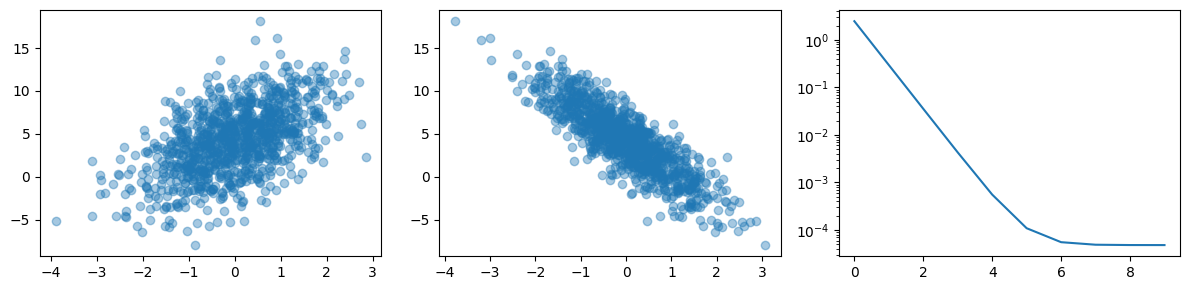

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_train, noise, w_gen, b_gen = 1000, 0.01, np.array([2.0, -3.4]).reshape((-1,1)), 4.2
rng = np.random.default_rng(0)
Xtr = rng.standard_normal((n_train, len(w_gen)))
ytr = Xtr @ w_gen + b_gen + rng.standard_normal((n_train, 1)) * noise

w, b, lr, epochs, losses = rng.normal(0,0.01,(2,1)), np.zeros((1,)), 0.1, 100, []
for epoch in range(epochs):
  y_hat = Xtr @ w + b
  err = y_hat-ytr
  loss, w_grad, b_grad = (err ** 2 / 2).mean(), Xtr.T @ err / Xtr.shape[0], err.mean()
  w -= lr * w_grad
  b -= lr * b_grad
  if (epoch + 1) % 10 == 0:
    losses.append(loss)

print(w,b)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].scatter(Xtr[:, 0], ytr, alpha=0.4)
axes[1].scatter(Xtr[:, 1], ytr, alpha=0.4)
axes[2].semilogy(losses)
plt.tight_layout()

tensor([[ 1.9996],
        [-3.3999]], requires_grad=True) tensor([4.1993], requires_grad=True)


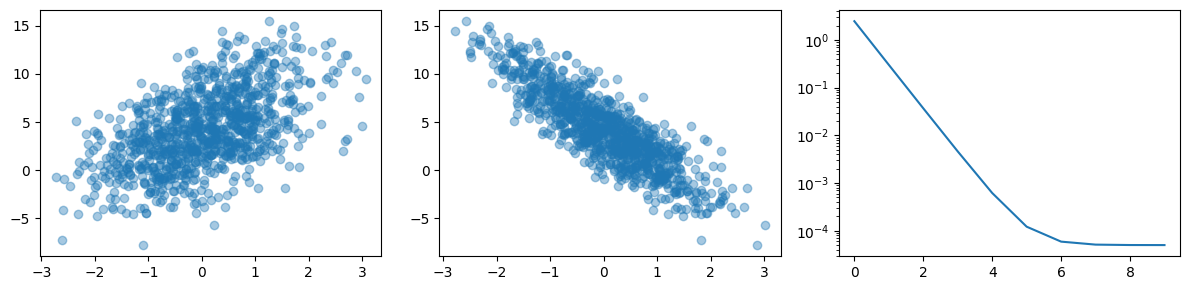

In [ ]:
import random
import torch
import matplotlib.pyplot as plt

num_train, num_val, noise = 1000, 1000, 0.01
w_gen, b_gen = torch.tensor([2, -3.4]), torch.tensor([4.2])
Xtr = torch.randn(num_train,len(w_gen))
ytr = torch.matmul(Xtr, w_gen.reshape((-1,1))) + b_gen + (torch.randn(num_train,1)) * noise

w, b = torch.normal(0,0.01,(2,1), requires_grad=True), torch.zeros(1, requires_grad=True)
lr, epochs, losses = 0.1, 100, []
for epoch in range(epochs):
  y_hat = torch.matmul(Xtr[:num_train], w) + b
  loss = ((y_hat-ytr[:num_train])**2/2).mean()
  loss.backward()
  with torch.no_grad(): # disable autograd
    w -= lr * w.grad
    b -= lr * b.grad
    w.grad.zero_()
    b.grad.zero_()
  if (epoch+1)%10==0:
    losses.append(loss.item())

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].scatter(Xtr[:num_train, 0], ytr[:num_train], alpha=0.4)
axes[1].scatter(Xtr[:num_train, 1], ytr[:num_train], alpha=0.4)
axes[2].semilogy(losses)
plt.tight_layout()
print(w, b)


Parameter containing:
tensor([[ 2.0002, -3.4000]], requires_grad=True) Parameter containing:
tensor([4.1999], requires_grad=True)


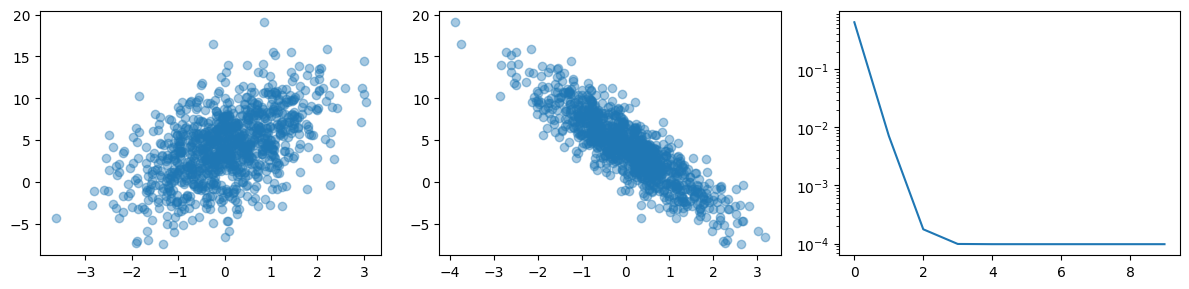

In [ ]:
import random
import torch
from torch import nn
import matplotlib.pyplot as plt

num_train, noise = 1000, 0.01
w_gen, b_gen = torch.tensor([2, -3.4]), torch.tensor([4.2])
Xtr = torch.randn(num_train,len(w_gen))
ytr = torch.matmul(Xtr, w_gen.reshape((-1,1))) + b_gen + (torch.randn(num_train,1)) * noise

net, lr, epochs, losses = nn.LazyLinear(1), 0.1, 100, []
loss, trainer = nn.MSELoss(), torch.optim.SGD(net.parameters(), lr=lr)
for epoch in range(epochs):
  trainer.zero_grad() # reset all gradients to zero
  l = loss(net(Xtr[:num_train]), ytr[:num_train]) # MSELoss on forward pass vs target
  l.backward() # calculate gradients
  trainer.step() # update parameters with gradients
  if (epoch+1)%10==0:
    losses.append(l.item())

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].scatter(Xtr[:num_train, 0], ytr[:num_train], alpha=0.4)
axes[1].scatter(Xtr[:num_train, 1], ytr[:num_train], alpha=0.4)
axes[2].semilogy(losses)
plt.tight_layout()
print(net.weight, net.bias)


- **Regularizer**:

$\BA
\dg{⇒}&E(w,b)=\/{1}{2N}\n{Xw+b\v{1}-y}^2+\/{λ}{2}\n{w}^2\dg{⇒}\/{1}{N}∇_wE=X^⊤(Xw+b\v{1}-y)+λw\dg{⇒}∇_bE=\/{1}{N}\v{1}^⊤(Xw+b\v{1}-y)
\EA$

[[ 1.98119784]
 [-3.36550256]] [4.19977457]


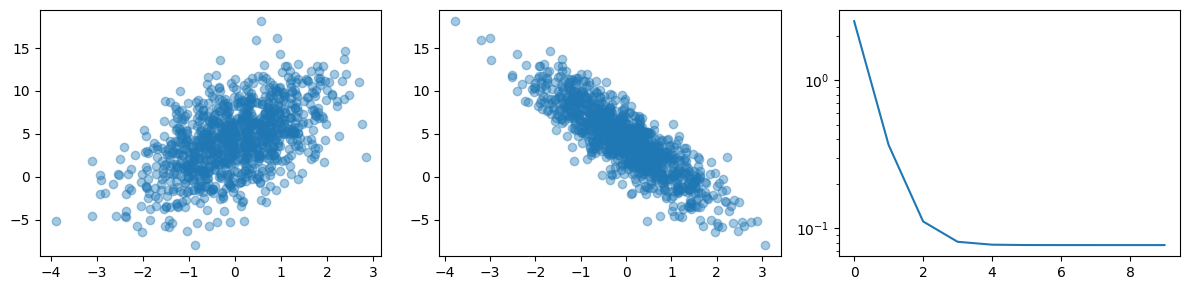

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_train, noise, w_gen, b_gen = 1000, 0.01, np.array([2.0, -3.4]).reshape((-1,1)), 4.2
rng = np.random.default_rng(0)
Xtr = rng.standard_normal((n_train, len(w_gen)))
ytr = Xtr @ w_gen + b_gen + rng.standard_normal((n_train, 1)) * noise

w, b, lr, epochs, losses, lambd = rng.normal(0,0.01,(2,1)), np.zeros((1,)), 0.1, 100, [], 0.01
for epoch in range(epochs):
  y_hat = Xtr @ w + b
  err = y_hat-ytr
  loss = (err ** 2 / 2).mean() + lambd * (w ** 2).sum() / 2
  w_grad, b_grad = Xtr.T @ err / Xtr.shape[0] + lambd * w, err.mean()
  w -= lr * w_grad
  b -= lr * b_grad
  if (epoch + 1) % 10 == 0:
    losses.append(loss)

print(w,b)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].scatter(Xtr[:, 0], ytr, alpha=0.4)
axes[1].scatter(Xtr[:, 1], ytr, alpha=0.4)
axes[2].semilogy(losses)
plt.tight_layout()

- **Nadaraya-Watson regression**: Parzen window KDE with RBF kernel.

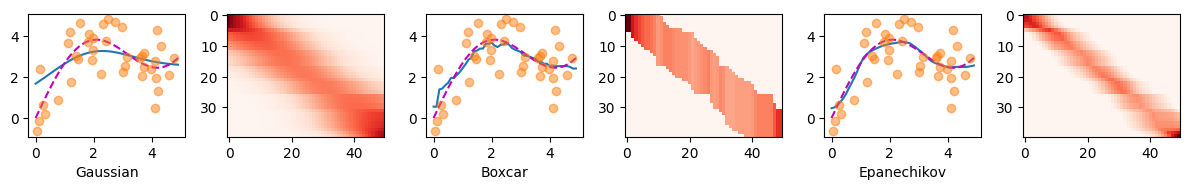

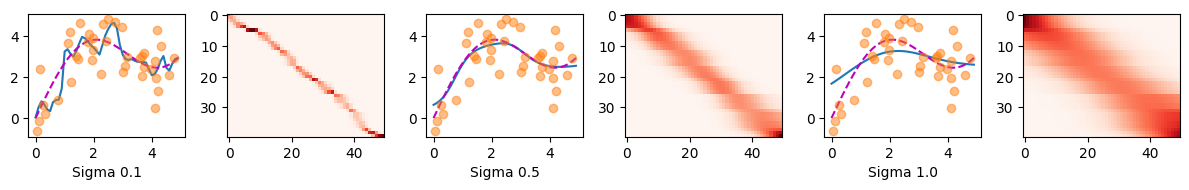

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def plot(x_train, y_train, x_val, y_val, kernels, names):
  fig, axes = plt.subplots(1, 6, figsize=(12, 2))
  for i, (kernel, name) in enumerate(zip(kernels, names)):
    y_hat, weights = nadaraya_watson(x_train, y_train, x_val, kernel)
    axes[2*i].plot(x_val.numpy(), y_hat.numpy(), label='y_hat')
    axes[2*i].plot(x_val.numpy(), y_val.numpy(), 'm--', label='y')
    axes[2*i].plot(x_train.numpy(), y_train.numpy(), 'o', alpha=0.5)
    axes[2*i].set_xlabel(name)
    pcm = axes[2*i+1].imshow(weights.numpy(), cmap='Reds', aspect='auto')
  fig.tight_layout()
  plt.show()

def f(x): return 2*torch.sin(x) + x

def gaussian(dist): return torch.exp(-dist**2/2)

def gaussian_w(sigma): return lambda dist:torch.exp(-dist**2/(2*sigma**2))

def boxcar(dist): return (torch.abs(dist)<1.0).float()

def epanechikov(dist): return torch.max(1-torch.abs(dist), torch.zeros_like(dist))

def nadaraya_watson(x_train, y_train, x_val, kernel):
  dists = x_train.reshape((-1,1)) - x_val.reshape((1,-1)) #(train_len, val_len)
  weights = kernel(dists).float()
  weights /= weights.sum(0) #normalize by column sums
  y_hat = y_train @ weights
  return y_hat, weights

kernels = (gaussian, boxcar, epanechikov)
names = ('Gaussian', 'Boxcar', 'Epanechikov')
x_train, _ = torch.sort(torch.rand(40)*5)
y_train = f(x_train) + torch.randn(40)
x_val = torch.arange(0, 5, 0.1)
y_val = f(x_val)
plot(x_train, y_train, x_val, y_val, kernels, names)

sigmas = (0.1, 0.5, 1.0)
names_w = [f'Sigma {sigma}' for sigma in sigmas]
kernels_w = [gaussian_w(sigma) for sigma in sigmas]
plot(x_train, y_train, x_val, y_val, kernels_w, names_w)

# D2L 4: Softmax Classification

**Classification**: non-invariant (susceptible to pixel translation) pixel-based classification. Targets are supplied as 0-9 for the ten categories of FashionMNIST.

$\BA
\dg{⇒}&\dg{\t{binary }}t_n∈\{0,1\}\dg{⇒}a_n=w^⊤x_n+b∈ℝ\dg{⇒}p(t_n=1|x_n)=y_n=\/{\e{a_n}}{1+\e{a_n}}\\
\dg{⇒}&\dg{\t{K-ary }}t_n∈\{0,1\}^K\dg{⇒}a_{nk}=w_k^⊤x_n+b_k\dg{⇒}p(t_{nk}=1|x_n)=y_{nk}=\/{\e{a_{nk}}}{\sum_j\e{a_{nj}}}\\
&\dg{⇒}W∈ℝ^{D×K}\dg{⇒}a_n=W^⊤x_n+b∈ℝ^K\dg{⇒\t{logits }}\red{A=XW+\v{1}_Nb^⊤}∈ℝ^{N×K}\\
\dg{⇒}&p(t_\m{D})=\prod_n\prod_ky_{nk}^{t_{nk}}\dg{⇒\t{cross entropy loss }}L:=-\ln p(t_\m{D})=-\sum_n\sum_kt_{nk}\ln y_{nk}=\sum_n[\ln\sum_j\e{a_{nj}}-\sum_kt_{nk}a_{nk}]\\
&\dg{⇒}\/{∂L}{∂a_{nk}}=y_{nk}-t_{nk}\dg{⇒}\red{\/{∂L}{∂A}=\t{Softmax}(A)-T}∈ℝ^{N×K}\dg{⇒}\BC
\/{∂L}{∂W}=(\/{∂A}{∂W})^⊤\/{∂L}{∂A}=X^⊤\/{∂L}{∂A}∈ℝ^{D×K}\\
\/{∂L}{∂b}=(\/{∂A}{∂b})^⊤\/{∂L}{∂A}=\v{1}_N^⊤\/{∂L}{∂A}∈ℝ^{K}
\EC\\
\EA$

- **Numpy broadcasting**: https://numpy.org/doc/stable/user/basics.broadcasting.html vector $b∈ℝ^K$ is broadcast into a matrix $\v{1}_Nb^⊤∈ℝ^{N×K}$ in `X @ W + b`.

- **Categorical target** `yb`$∈[0,9]^N$ serves as index of '1' in one-hot. Computing $\t{Softmax}(A)-T$ without computing and storing the one-hot matrix $T$ just uses `softmax(X@W+b)[np.arange(batch_size),yb] -= 1`.

- **Image flattening**: each image comes in (1,28,28) where dim=0 is grayscale (0-255), and is flattened to (784) for a total $K(D+1)=7850$ parameters.

train: (60000, 784) (60000,) test: (10000, 784) (10000,)
saved loss_curve.png
saved predictions.png
final test accuracy: 0.8293


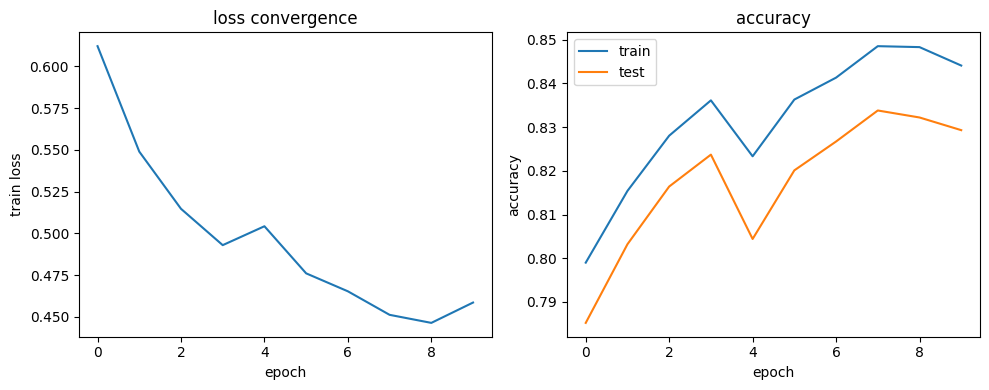

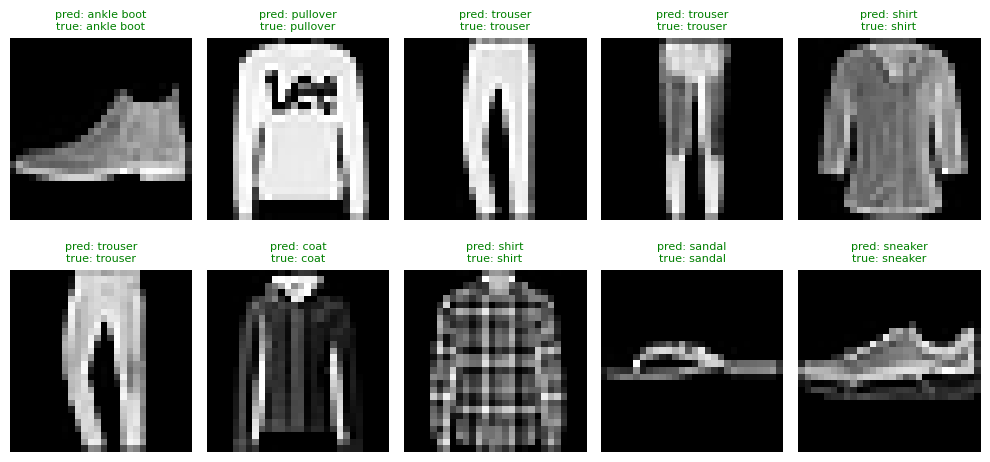

In [ ]:
import numpy as np
import torch
from torchvision import datasets
import matplotlib.pyplot as plt

CLASS_NAMES = ["t-shirt", "trouser", "pullover", "dress", "coat",
               "sandal", "shirt", "sneaker", "bag", "ankle boot"]

def load_data(dir="data/fashion-mnist-torch"):
  train_data = datasets.FashionMNIST(root=dir, train=True, download=True)
  test_data = datasets.FashionMNIST(root=dir, train=False, download=True)
  X_train = train_data.data.numpy().astype(np.float32).reshape(-1,784) / 255.0
  y_train = train_data.targets.numpy().astype(np.int64)
  X_test = test_data.data.numpy().astype(np.float32).reshape(-1,784) / 255.0
  y_test = test_data.targets.numpy().astype(np.int64)
  return X_train, y_train, X_test, y_test

def softmax(logits):
  z = logits - logits.max(axis=1, keepdims=True)
  return np.exp(z) / np.exp(z).sum(axis=1, keepdims=True)

def train(X_train, y_train, X_test, y_test, lr=0.1, batch_size=256, epochs=10, seed=0):
  rng = np.random.default_rng(seed)
  n, d, k = X_train.shape[0], X_train.shape[1], int(y_train.max() + 1) #y_train not one-hot
  W, b = rng.normal(0,0.01,(d,k)), np.zeros(k)

  train_losses, train_accs, test_accs = [], [], []
  for epoch in range(epochs):
    idx = rng.permutation(n)
    for batch_i in range(0, n, batch_size):
      batch = idx[batch_i : batch_i+batch_size]
      Xb, yb = X_train[batch], y_train[batch]
      Pb = softmax(Xb @ W + b) # numpy broadcasting b into matrix
      logits_grad = Pb.copy()
      logits_grad[np.arange(Xb.shape[0]), yb] -= 1 # Softmax(A)-T
      logits_grad /= Xb.shape[0]
      W_grad = Xb.T @ logits_grad
      b_grad = logits_grad.sum(axis=0)
      W -= lr * W_grad
      b -= lr * b_grad
    P_train = softmax(X_train @ W + b)
    P_test = softmax(X_test @ W + b)
    train_losses.append(-np.log(P_train[np.arange(y_train.shape[0]), y_train] + 1e-12).mean())
    train_accs.append((P_train.argmax(axis=1) == y_train).mean())
    test_accs.append((P_test.argmax(axis=1) == y_test).mean())
  return W, b, train_losses, train_accs, test_accs

def plot_curves(train_losses, train_accs, test_accs, out="loss_curve.png"):
  fig, axes = plt.subplots(1, 2, figsize=(10, 4))
  axes[0].plot(train_losses)
  axes[0].set(xlabel="epoch", ylabel="train loss", title="loss convergence")
  axes[1].plot(train_accs, label="train")
  axes[1].plot(test_accs, label="test")
  axes[1].set(xlabel="epoch", ylabel="accuracy", title="accuracy")
  axes[1].legend()
  fig.tight_layout()
  fig.savefig(out, dpi=100)
  print("saved", out)

def plot_predictions(X_test, y_test, W, b, out="predictions.png", n=10):
  P = softmax(X_test[:n] @ W + b)
  pred = P.argmax(axis=1)
  fig, axes = plt.subplots(2, 5, figsize=(10, 5))
  for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"pred: {CLASS_NAMES[pred[i]]}\ntrue: {CLASS_NAMES[y_test[i]]}",
                fontsize=8,
                color="green" if pred[i] == y_test[i] else "red")
    ax.axis("off")
  fig.tight_layout()
  fig.savefig(out, dpi=100)
  print("saved", out)

X_train, y_train, X_test, y_test = load_data()
print("train:", X_train.shape, y_train.shape,
      "test:", X_test.shape, y_test.shape)

W, b, train_losses, train_accs, test_accs = train(
    X_train, y_train, X_test, y_test, lr=0.1, batch_size=256, epochs=10)

plot_curves(train_losses, train_accs, test_accs)
plot_predictions(X_test, y_test, W, b)
print(f"final test accuracy: {test_accs[-1]:.4f}")

- **Tensor**: `net(X)`$∈ℝ^{D×10}$ returns a batch size $D$ `nn.Tensor` where each row is a Softmax. `net(X).argmax(1)==y`$∈\{0,1\}^D$ gives a boolean vector. `tensor.item()` returns the Python value. `tensor.numel()` returns the number of elements in a tensor.

test accuracy: 0.8187


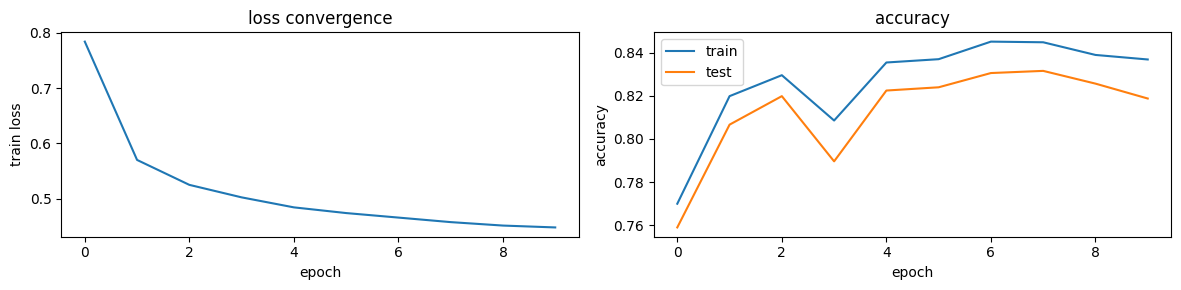

In [ ]:
import torch
from torch import nn
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

def load_data(dir="data/fashion-mnist-torch"):
  train_data = datasets.FashionMNIST(root=dir, train=True, download=True)
  test_data = datasets.FashionMNIST(root=dir, train=False, download=True)
  train_loader = DataLoader(TensorDataset(train_data.data.float().div(255).reshape(-1,784), train_data.targets), batch_size=256, shuffle=True)
  test_loader = DataLoader(TensorDataset(test_data.data.float().div(255).reshape(-1,784), test_data.targets), batch_size=256)
  return train_loader, test_loader

def accuracy(loader, net):
  correct = total = 0
  with torch.no_grad():
    for X,y in loader:
      correct += (net(X).argmax(1)==y).sum().item()
      total += y.numel()
  return correct/total

def train(train_loader, test_loader, lr=0.1, epochs=10):
  net = nn.LazyLinear(10)
  with torch.no_grad(): # reduce memory use by asserting no grad calculations
    net(torch.zeros(1,784))
  nn.init.normal_(net.weight, 0, 0.01)
  nn.init.zeros_(net.bias)

  loss_fn = nn.CrossEntropyLoss() # takes pre-activations [a_k], and compares softmax([a_k]) vs [t_k]
  trainer = torch.optim.SGD(net.parameters(), lr)
  train_losses, train_accs, test_accs = [], [], []

  for epoch in range(epochs):
    net.train() # optional good practice required by batch norm and dropout
    total_loss, n_batches = 0.0, 0
    for X,y in train_loader: # for each batch
      trainer.zero_grad() # zero the grads
      l = loss_fn(net(X), y) # pass in [a_k] and [t_k]
      l.backward() # calculate grads
      trainer.step() # update weights
      total_loss += l.item()
      n_batches += 1
    train_losses.append(total_loss/n_batches)
    train_accs.append(accuracy(train_loader, net))
    test_accs.append(accuracy(test_loader, net))
  return train_losses, train_accs, test_accs

train_loader, test_loader = load_data()
train_losses, train_accs, test_accs = train(train_loader, test_loader)
fig, axes = plt.subplots(1, 2, figsize=(12,3))
axes[0].plot(train_losses)
axes[0].set(xlabel="epoch", ylabel="train loss", title="loss convergence")
axes[1].plot(train_accs, label="train")
axes[1].plot(test_accs, label="test")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="accuracy")
axes[1].legend()
fig.tight_layout()
fig.savefig("loss_curve.png", dpi=100)
print(f"test accuracy: {test_accs[-1]:.4f}")

# D2L 5: MLP

**Multilayer perceptron**: RKHS single arbitrarily wide layer of RBFs can model any funtion (universal approximator). We can approximate many functions more compactly using deeper networks. MLP is a multi-hidden layer architecture where each hidden layer consists of linear pre-activation followed by ReLU $z^{(l)}=\t{ReLU}(a^{(l)}=W^{(l)}z^{(l-1)}+b^{(l)})$

$\BA
\dg{⇒}&x∈ℝ^{784}→\block{z_j=\t{ReLU}(a_j=w_j^⊤x+b)}→z∈ℝ^{256}→\block{y_k=w_k^⊤z}→y∈ℝ^{10}
\EA$

- **ReLU decision boundary**: Hyperplane decision boundary $w^⊤x+b$ classifies point $x$ by which side the point sits. ReLU "folds" $\{x∈ℝ^{784}|w^⊤x+b≤0\}$ into zero so that all points in that region are indistinguishable to this inactive ReLU. Turning on and off 256 of these hyperplanes partitions the $ℝ^{784}$ image space into at most $2^{256}$ polyhedral cells made by arrangement of 256 hyperplanes. The second layer computes combinations of active ReLUs for the final classification.

- **Separability**: $x∈ℝ^{784}$ codes pixel intensities where higher-order features are entangled and cannot be linearly separated. A LazyLinear(10) > softmax system performs pixel intensity correlation. It cannot learn the XOR problem.
$ℝ^{256}$ feature space may encode higher-order features like edge, stroke, loop detection in an emergent (non-designed) way. A LazyLinear(256) > ReLU > LazyLinear(10) > softmax system non-linearly projects $ℝ^{784}$ onto $ℝ^{256}$ in the most efficient way to achieve linear separability in $ℝ^{256}$ space through gradient descent. Layer 2 looks at the 256 features instead of pixels. MLP has no predictable or interpretable way to control what each of the 256 features are (unlike CNN inductive biases). Without inductive biases MLP requires synthetic data augmentation (apply rotations, shifts) to teach it invariances.

- **Hidden units**: baseline single-layer `LazyLinear(10)` model with 7850 parameters reaches 81.87% test accuracy. Model with 32 hidden units $(D+1)K_1+(K_1+1)K_2=25120+330=25,450$ parameters we reach 83.41% accuracy. 128 units attains 85.33% accuracy. More hidden units add greater nonlinear capacity whereas fewer units withdraw back toward linear baseline.
With 32 hidden units the network must learn higher order features by projecting $ℝ^{784}$ onto $ℝ^{32}$, which creates a bottleneck where there may not be enough to linearly separate subtle variations of 10 classes. However the information bottleneck acts as a low-pass filter that ignores high-frequency noise and therefore acts as regularization.

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 167kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.15MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.4MB/s]


test accuracy: 0.8451


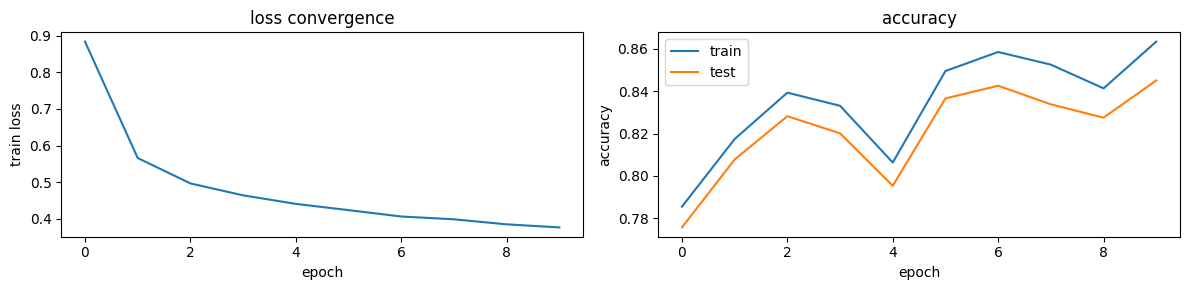

In [ ]:
import torch
from torch import nn
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

def load_data(dir="data/fashion-mnist-torch"):
  train_data = datasets.FashionMNIST(root=dir, train=True, download=True)
  test_data = datasets.FashionMNIST(root=dir, train=False, download=True)
  train_loader = DataLoader(TensorDataset(train_data.data.float().div(255).reshape(-1,784), train_data.targets), batch_size=256, shuffle=True)
  test_loader = DataLoader(TensorDataset(test_data.data.float().div(255).reshape(-1,784), test_data.targets), batch_size=256)
  return train_loader, test_loader

def accuracy(loader, net):
  correct = total = 0
  with torch.no_grad():
    for X,y in loader:
      correct += (net(X).argmax(1)==y).sum().item()
      total += y.numel()
  return correct/total

def network():
  net = nn.Sequential(nn.LazyLinear(128), nn.ReLU(), nn.LazyLinear(10))
  with torch.no_grad():
    net(torch.zeros(1,784))
  for m in net.modules():
    if isinstance(m, nn.LazyLinear):
      nn.init.normal_(m.weight, 0, 0.01)
      nn.init.zeros_(m.bias)
  return net

def train(net, train_loader, test_loader, lr=0.1, epochs=10):
  loss_fn = nn.CrossEntropyLoss()
  trainer = torch.optim.SGD(net.parameters(), lr)
  train_losses, train_accs, test_accs = [], [], []

  for epoch in range(epochs):
    net.train()
    total_loss, n_batches = 0.0, 0
    for X,y in train_loader:
      trainer.zero_grad()
      l = loss_fn(net(X), y)
      l.backward()
      trainer.step()
      total_loss += l.item()
      n_batches += 1
    train_losses.append(total_loss/n_batches)
    train_accs.append(accuracy(train_loader, net))
    test_accs.append(accuracy(test_loader, net))
  return train_losses, train_accs, test_accs

train_loader, test_loader = load_data()
train_losses, train_accs, test_accs = train(network(), train_loader, test_loader)
fig, axes = plt.subplots(1, 2, figsize=(12,3))
axes[0].plot(train_losses)
axes[0].set(xlabel="epoch", ylabel="train loss", title="loss convergence")
axes[1].plot(train_accs, label="train")
axes[1].plot(test_accs, label="test")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="accuracy")
axes[1].legend()
fig.tight_layout()
fig.savefig("loss_curve.png", dpi=100)
print(f"test accuracy: {test_accs[-1]:.4f}")


- **Activation functions**: Without nonlinear activation function, multiple linear layers collapse into one. Activation function choice matters through gradient health across depth. Logistic sigmoid derivative maxes at 0.25, so gradients vanish across layers even if pre-activations aren't extreme. This is why deep networks failed prior to 2010 introduction of ReLU.

  - **Symmetry**: if weights are initialized to the same constant $c$, they update together and never deviate from each other. Modern practice pairs ReLU with He initialization, tanh with Xavier initialization.

- **Generalization** means ability of the model trained on statistical principles to make predictions beyond the training set. Deep networks trained through SGD generalize remarkably well across prediction problems without coherent scientific theory for (1) why we can fit them to training data to arbitrarily low loss and (2) why the resulting model generalize to unseen examples. When the chosen model can achieve zero training error, the difference between training fit and test fit is the generalization gap.

  - **Double descent**: classical learning theory prescribes generalization gap with reducing overfitting.
  However it is often the case that despite perfect training fit, we can reduce generalization error further by adding layers, nodes, training epochs.

  - **Nonparametric**: because deep networks have more parameters than training data, they tend to interpolate training data and behaving like nonparametric models (such as kernel density estimator).

  - **Regularization**: modern deep networks rely on data augmentation as the main method of shrinking the generalization gap. Mild decay is used to prevent weights from growing too large for training stabilization. SGD/Adam prefers flat minima and minimum norm solutions, which acts as implicit regluarization of the optimization algorithm.
  Dropout is used for MLPs, and is implemented by inserting `nn.Dropout(0.5)` after `nn.ReLU()`. It is only used on training data and not on testing data.

# D2L 7, 8: CNN

**CNN**: Let $X$ be input image and $[X]_{i,j}$ be pixel value, $H$ be convolutional layer with learnable weights/parameters $V$, which is the size $Δ$ convolution kernel/filter. The cross-correlation operation to compute translation-invariant features use the same filter (shared weights) for each pixel. This CNN **inductive bias** leads to drastically reduced parameter set to train.

$\BA
\dg{⇒}&[H]_{i,j}=u+\sum_{a=-Δ}^Δ\sum_{b=-Δ}^Δ[V]_{a,b}[X]_{i+a,j+b}\dg{\t{ where }}[V]_{a,b}=0\ ∀|a|>Δ,|b|>Δ\\
\dg{⇒}&\dg{\t{I/O color channels }}c,d\dg{⇒}[H]_{i,j,d}=u+\sum_{a=-Δ}^Δ\sum_{b=-Δ}^Δ\sum_c[V]_{a,b,c,d}[X]_{i+a,j+b,c}
\EA$

In [ ]:
import torch
from torch import nn

def corr2d(X, K):
  h, w = K.shape
  Y = torch.zeros((X.shape[0]-h+1, X.shape[1]-w+1))
  for i in range(Y.shape[0]):
    for j in range(Y.shape[1]):
      Y[i,j] = (X[i:i+h, j:j+w] * K).sum()
  return Y

class Conv2D(nn.Module):
  def __init__(self, kernel_size):
    super().__init__()
    self.weight = nn.Parameter(torch.rand(kernel_size))
    self.bias = nn.Parameter(torch.zeros(1))

  def forward(self, X):
    return corr2d(X, self.weight) + self.bias

- **Padding and stride**: `nn.LazyConv2d(1, kernel_size=(3,3), padding=(1,1), stride=1)` creates a convolutional layer with 1 output channel, 2×2 kernel, 1 pixel padding to top bottom left and right, and moving in single step strides.

$\BA
\dg{⇒}&\dg{\t{dimensions: input }}(h_x,w_x)\dg{⇒\t{padding }}(h_p,w_p)\dg{⇒\t{kernel }}(h_k,w_k)\dg{⇒\t{stride }}(h_s,w_s)\\
&\dg{⇒}\red{\left(\left\lfloor\/{h_x+2h_p-h_k}{h_s}\right\rfloor+1\right)×\left(\left\lfloor\/{w_x+2w_p-w_k}{w_s}\right\rfloor+1\right)}
\EA$

- **Channels (feature maps)**: Each combination of input and output channel requires one kernel $[V]_{a,b}$. With two input and one output, the output is sum of convolution of input against each kernel. $[X]\ast[V_1]+[X]\ast[V_2]$.

  - **1×1 kernel**: requires $c×d$ weights plus bias, and is used to perform channel calculations.

- **Dropout**: only useful when generalization gap between test accuracy and training accuracy is wide. Disabling dropout during evaluation phase requires `net.eval()`, which needs to be nested in a `was_training = net.training` and `net.train(was_training)` code block.

- **LeNet**: 1995. Designed by trial and error, the number of feature maps was chosen empirically.

$\BA
\dg{⇒}&\block{28×28}→\block{5×5\t{ Conv}(\t{out}=6,\t{pad}=2)}→\block{2×2\t{ Avg}(\t{stride}=2)}→\block{5×5\t{ Conv}(\t{out}=16)}→\block{2×2\t{ Avg}(\t{stride}=2)}\\
&→\block{\t{FC}(120)}→\block{\t{FC}(84)}→\block{\t{FC}(10)}
\EA$

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 338kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.17MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.85MB/s]


Conv2d output shape: 	 torch.Size([1, 6, 28, 28])
ReLU output shape: 	 torch.Size([1, 6, 28, 28])
MaxPool2d output shape: 	 torch.Size([1, 6, 14, 14])
Conv2d output shape: 	 torch.Size([1, 16, 10, 10])
ReLU output shape: 	 torch.Size([1, 16, 10, 10])
MaxPool2d output shape: 	 torch.Size([1, 16, 5, 5])
Flatten output shape: 	 torch.Size([1, 400])
Linear output shape: 	 torch.Size([1, 120])
ReLU output shape: 	 torch.Size([1, 120])
Linear output shape: 	 torch.Size([1, 84])
ReLU output shape: 	 torch.Size([1, 84])
Linear output shape: 	 torch.Size([1, 10])
test accuracy: 0.8675


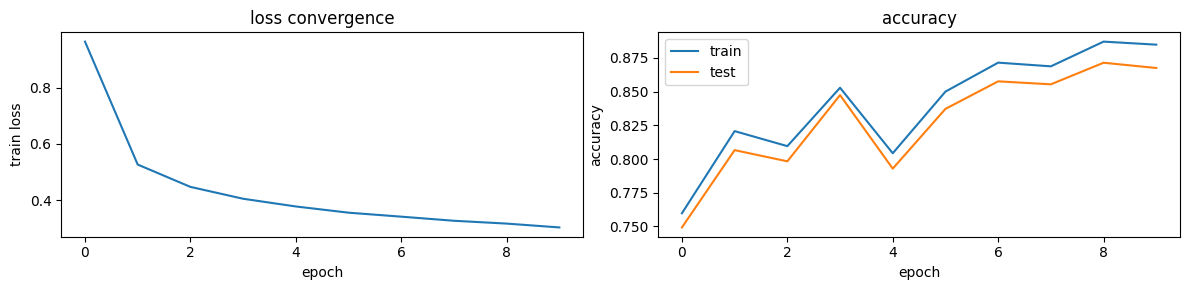

In [ ]:
import torch
from torch import nn
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

def load_data(dir="data/fashion-mnist-torch"):
  train_data = datasets.FashionMNIST(root=dir, train=True, download=True)
  test_data = datasets.FashionMNIST(root=dir, train=False, download=True)
  train_loader = DataLoader(TensorDataset(train_data.data.float().div(255).reshape(-1,1,28,28), train_data.targets), batch_size=256, shuffle=True)
  test_loader = DataLoader(TensorDataset(test_data.data.float().div(255).reshape(-1,1,28,28), test_data.targets), batch_size=256)
  return train_loader, test_loader

def accuracy(loader, net):
  correct = total = 0
  with torch.no_grad():
    for X,y in loader:
      correct += (net(X).argmax(1)==y).sum().item()
      total += y.numel()
  return correct/total

def network(): #LeNET with ReLU ad MaxPool
  net = nn.Sequential(nn.Conv2d(1, 6, kernel_size=5, padding=2), #6x28x28
                      nn.ReLU(),
                      nn.MaxPool2d(kernel_size=2, stride=2), #6x14x14
                      nn.Conv2d(6, 16, kernel_size=5), #16x10x10
                      nn.ReLU(),
                      nn.MaxPool2d(kernel_size=2, stride=2), #16x5x5
                      nn.Flatten(),
                      nn.Linear(16*5*5,120),
                      nn.ReLU(),
                      nn.Linear(120,84),
                      nn.ReLU(),
                      nn.Linear(84,10)
                      )
  X_dummy = torch.rand(size=(1,1,28,28), dtype=torch.float32)
  with torch.no_grad():
    for layer in net:
      X_dummy = layer(X_dummy)
      print(layer.__class__.__name__,'output shape: \t',X_dummy.shape)
  for m in net.modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
      nn.init.xavier_uniform_(m.weight)
      nn.init.zeros_(m.bias)
  return net

def train(net, train_loader, test_loader, lr=0.1, epochs=10):
  train_losses, train_accs, test_accs = [], [], []
  loss_fn = nn.CrossEntropyLoss()
  trainer = torch.optim.SGD(net.parameters(), lr)
  for epoch in range(epochs):
    total_loss, n_batches = 0.0, 0
    for X,y in train_loader:
      trainer.zero_grad()
      l = loss_fn(net(X), y)
      l.backward()
      trainer.step()
      total_loss += l.item()
      n_batches += 1
    train_losses.append(total_loss/n_batches)
    train_accs.append(accuracy(train_loader, net))
    test_accs.append(accuracy(test_loader, net))
  return train_losses, train_accs, test_accs

train_loader, test_loader = load_data()
train_losses, train_accs, test_accs = train(network(), train_loader, test_loader) #2min, 0.8674
fig, axes = plt.subplots(1, 2, figsize=(12,3))
axes[0].plot(train_losses)
axes[0].set(xlabel="epoch", ylabel="train loss", title="loss convergence")
axes[1].plot(train_accs, label="train")
axes[1].plot(test_accs, label="test")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="accuracy")
axes[1].legend()
fig.tight_layout()
fig.savefig("loss_curve.png", dpi=100)
print(f"test accuracy: {test_accs[-1]:.4f}")


- **AlexNet**: 2012. Introduced use of ReLU and Maxpool instead of sigmoid and AvgPool. Additionally brought deeper depth. Dropout(0.5) is used between FC (Linear→ReLU) blocks to prevent overfitting.
These concepts were popularized after release of TensorFlow 2016.

$\BA
\dg{⇒}&\block{3×224×224}→\block{11×11\t{ Conv}(\t{out}=96,\t{stride}=4)}→\block{3×3\t{ Max}(2)}→\block{5×5\t{ Conv}(\t{out}=256,\t{pad}=2)}\\
&→\block{3×3\t{ Max}(2)}→\block{3×3\t{ Conv}(\t{out}=384,\t{pad}=1)}→\block{3×3\t{ Conv}(\t{out}=384,\t{pad}=1)}\\
&→\block{3×3\t{ Conv}(\t{out}=256,\t{pad}=1)}→\block{3×3\t{ Max}(2)}→\block{\t{FC}(4096)}→\block{\t{FC}(4096)}→\block{\t{FC}(1000)}
\EA$

- **Mini-VGG**: 3x3 receptive fields are the smallest kernel that captures local patterns. VGG stacking two 3x3 convolutional layers per block gives one 5x5 field. AlexNet MaxPool is better than AvgPool at preserving strong activations against vanishing gradients along with ReLU. 117k parameters. Training time bottleneck at FC parameters training.

  - To make it train faster (less accuracy), reduce each block to only have 1 convolutional layer and half the channels. Use `torch.optim.Adam` or `torch.optimal.SGD(momentum=0.9)` trainers.

  - To make it more accurate, add a third block. Add `nn.BatchNorm(32)` before `nn.ReLU()` to allow better stability at a cost of longer training time (14min vs 11min).

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 229kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.26MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.4MB/s]


test accuracy: 0.9126


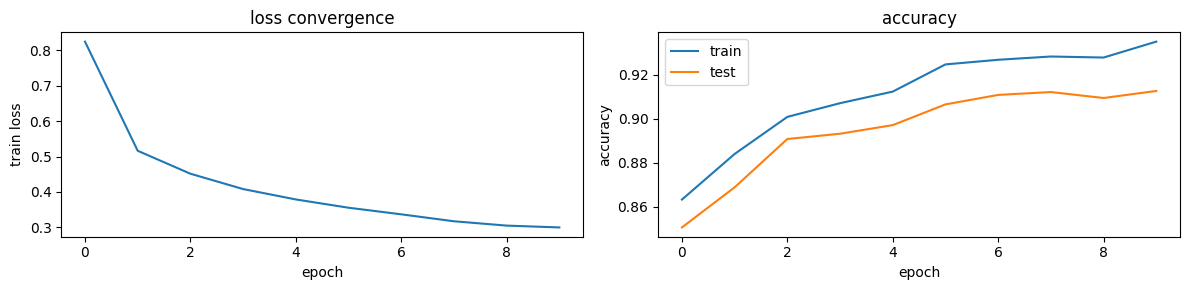

In [ ]:
import torch
from torch import nn
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

def load_data(dir="data/fashion-mnist-torch"):
  train_data = datasets.FashionMNIST(root=dir, train=True, download=True)
  test_data = datasets.FashionMNIST(root=dir, train=False, download=True)
  train_loader = DataLoader(TensorDataset(train_data.data.float().div(255).reshape(-1,1,28,28), train_data.targets), batch_size=256, shuffle=True)
  test_loader = DataLoader(TensorDataset(test_data.data.float().div(255).reshape(-1,1,28,28), test_data.targets), batch_size=256)
  return train_loader, test_loader

def accuracy(loader, net):
  correct = total = 0
  was_training = net.training
  net.eval() # eval mode for nn.BatchNorm2d and nn.Dropout
  with torch.no_grad():
    for X,y in loader:
      correct += (net(X).argmax(1)==y).sum().item()
      total += y.numel()
  net.train(was_training)
  return correct/total

def network(): #mini-VGG
  net = nn.Sequential(nn.Conv2d(1, 16, kernel_size=3, padding=1), #16x28x28
                      nn.BatchNorm2d(16),
                      nn.ReLU(),
                      nn.Conv2d(16, 16, kernel_size=3, padding=1), #16x28x28
                      nn.BatchNorm2d(16),
                      nn.ReLU(),
                      nn.MaxPool2d(kernel_size=2, stride=2), #16x14x14
                      nn.Conv2d(16, 32, kernel_size=3, padding=1), #32x14x14
                      nn.BatchNorm2d(32),
                      nn.ReLU(),
                      nn.Conv2d(32, 32, kernel_size=3, padding=1), #32x14x14
                      nn.BatchNorm2d(32),
                      nn.ReLU(),
                      nn.MaxPool2d(kernel_size=2, stride=2), #32x7x7
                      nn.Flatten(),
                      nn.Linear(32*7*7, 64),
                      nn.ReLU(),
                      nn.Dropout(0.5), # prevents FC overfitting
                      nn.Linear(64,10)
                      )
  X_dummy = torch.rand(size=(1,1,28,28), dtype=torch.float32)
  with torch.no_grad():
    for layer in net:
      X_dummy = layer(X_dummy)
      # print(layer.__class__.__name__,'output shape: \t',X_dummy.shape)
  for m in net.modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
      nn.init.xavier_uniform_(m.weight)
      nn.init.zeros_(m.bias)
  return net

def train(net, train_loader, test_loader, lr=0.001, epochs=10): # Adam starts with very low lr
  train_losses, train_accs, test_accs = [], [], []
  loss_fn = nn.CrossEntropyLoss()
  trainer = torch.optim.Adam(net.parameters(), lr) # Adam lr trainer
  for epoch in range(epochs):
    total_loss, n_batches = 0.0, 0
    for X,y in train_loader:
      trainer.zero_grad()
      l = loss_fn(net(X), y)
      l.backward()
      trainer.step()
      total_loss += l.item()
      n_batches += 1
    train_losses.append(total_loss / n_batches)
    train_accs.append(accuracy(train_loader, net))
    test_accs.append(accuracy(test_loader, net))
  return train_losses, train_accs, test_accs

train_loader, test_loader = load_data()
train_losses, train_accs, test_accs = train(network(), train_loader, test_loader) #23min, 0.9126
fig, axes = plt.subplots(1, 2, figsize=(12,3))
axes[0].plot(train_losses)
axes[0].set(xlabel="epoch", ylabel="train loss", title="loss convergence")
axes[1].plot(train_accs, label="train")
axes[1].plot(test_accs, label="test")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="accuracy")
axes[1].legend()
fig.tight_layout()
fig.savefig("loss_curve.png", dpi=100)
print(f"test accuracy: {test_accs[-1]:.4f}")

- **GoogLeNet**: outputs of the four branches preserve spatial dimensions and are concatenated channel-wise.

$\BA
\dg{⇒}&\dg{\t{inception block }}\t{input}→\left\{\BA
\dg{\t{pixel details}}&\block{1×1\t{ Conv}}\\
\dg{\t{edges/corners}}&\block{1×1\t{ Conv}}→\block{3×3\t{ Conv}(\t{pad}=1)}\\
\dg{\t{larger structures}}&\block{1×1\t{ Conv}}→\block{5×5\t{ Conv}(\t{pad}=2)}\\
\dg{\t{broader context}}&\block{3×3\t{ Max}(\t{pad}=1)}→\block{1×1\t{ Conv}}
\EA\right\}→\t{concat channels}\\
\dg{⇒}&\dg{\t{GoogLeNet }}\block{7×7\t{ Conv}}→\block{3×3\t{ Max}}→\block{1×1\t{ Conv}}→\block{3×3\t{ Conv}}→\block{3×3\t{ Max}}→\block{2×\t{ Inception}}→\block{3×3\t{ Max}}\\
&→\block{5×\t{ Inception}}→\block{3×3\t{ Max}}→\block{2×\t{ Inception}}→\block{\t{GAP}}→\block{\t{FC}}
\EA$

- **Mini-GoogLeNet** performs similarly to mini-VGG on FashionMNIST. It shines if the dataset has wildly different scales (bigger or smaller). Mini-GoogLeNet only has 11k parameters (vs 117k) represents a massive fewer parameters and virtually no risk to overfit.

test accuracy: 0.8794


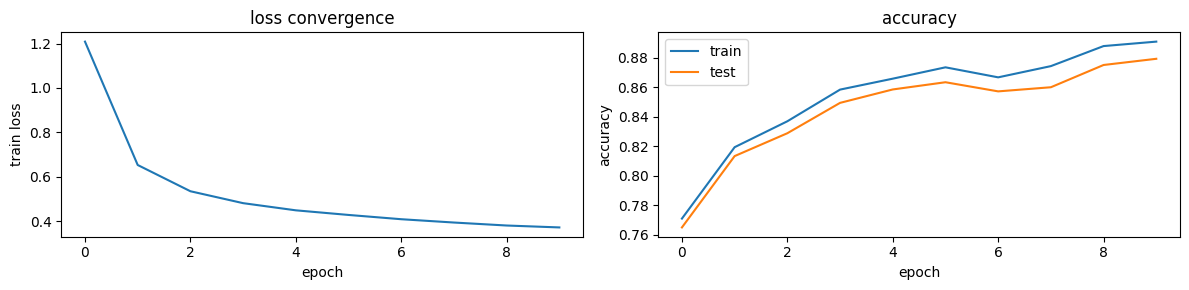

In [ ]:
import torch
from torch import nn
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

def load_data(dir="data/fashion-mnist-torch"):
  train_data = datasets.FashionMNIST(root=dir, train=True, download=True)
  test_data = datasets.FashionMNIST(root=dir, train=False, download=True)
  train_loader = DataLoader(TensorDataset(train_data.data.float().div(255).reshape(-1,1,28,28), train_data.targets), batch_size=256, shuffle=True)
  test_loader = DataLoader(TensorDataset(test_data.data.float().div(255).reshape(-1,1,28,28), test_data.targets), batch_size=256)
  return train_loader, test_loader

def accuracy(loader, net):
  correct = total = 0
  was_training = net.training
  net.eval()
  with torch.no_grad():
    for X,y in loader:
      correct += (net(X).argmax(1)==y).sum().item()
      total += y.numel()
  net.train(was_training)
  return correct/total

class Inception(nn.Module):
  def __init__(self, c1, c2, c3, c4):
    super().__init__()
    self.b1 = nn.LazyConv2d(c1, kernel_size=1)
    self.b2 = nn.Sequential(nn.LazyConv2d(c2[0], kernel_size=1), nn.ReLU(), nn.LazyConv2d(c2[1], kernel_size=3, padding=1))
    self.b3 = nn.Sequential(nn.LazyConv2d(c3[0], kernel_size=1), nn.ReLU(), nn.LazyConv2d(c3[1], kernel_size=5, padding=2))
    self.b4 = nn.Sequential(nn.MaxPool2d(kernel_size=3, stride=1, padding=1), nn.LazyConv2d(c4, kernel_size=1))
  def forward(self, X):
    return torch.cat([self.b1(X), self.b2(X), self.b3(X), self.b4(X)], dim=1)

def network(): #mini-GoogLeNet
  net = nn.Sequential(nn.Conv2d(1, 16, kernel_size=3, padding=1), #16x28x28
                      nn.BatchNorm2d(16),
                      nn.ReLU(),
                      nn.MaxPool2d(2), #16x14x14
                      Inception(16, (8,16), (4,8), 8), #48x14x14
                      nn.BatchNorm2d(48),
                      nn.ReLU(),
                      nn.MaxPool2d(2), #48x7x7
                      Inception(24, (16,24), (8,8), 8), #64x7x7
                      nn.BatchNorm2d(64),
                      nn.ReLU(),
                      nn.AdaptiveAvgPool2d((1,1)), #64x1x1
                      nn.Flatten(),
                      nn.Dropout(0.3),
                      nn.Linear(64, 10)
                      )
  X_dummy = torch.rand(size=(1,1,28,28), dtype=torch.float32)
  with torch.no_grad():
    for layer in net:
      X_dummy = layer(X_dummy)
      # print(layer.__class__.__name__,'output shape: \t',X_dummy.shape)
  for m in net.modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
      nn.init.xavier_uniform_(m.weight)
      nn.init.zeros_(m.bias)
  return net

def train(net, train_loader, test_loader, lr=0.001, epochs=10): # Adam starts with very low lr
  train_losses, train_accs, test_accs = [], [], []
  loss_fn = nn.CrossEntropyLoss()
  trainer = torch.optim.Adam(net.parameters(), lr) # Adam lr trainer
  for epoch in range(epochs):
    total_loss, n_batches = 0.0, 0
    for X,y in train_loader:
      trainer.zero_grad()
      l = loss_fn(net(X), y)
      l.backward()
      trainer.step()
      total_loss += l.item()
      n_batches += 1
    train_losses.append(total_loss / n_batches)
    train_accs.append(accuracy(train_loader, net))
    test_accs.append(accuracy(test_loader, net))
  return train_losses, train_accs, test_accs

train_loader, test_loader = load_data()
train_losses, train_accs, test_accs = train(network(), train_loader, test_loader) #21min, 0.8794
fig, axes = plt.subplots(1, 2, figsize=(12,3))
axes[0].plot(train_losses)
axes[0].set(xlabel="epoch", ylabel="train loss", title="loss convergence")
axes[1].plot(train_accs, label="train")
axes[1].plot(test_accs, label="test")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="accuracy")
axes[1].legend()
fig.tight_layout()
fig.savefig("loss_curve.png", dpi=100)
print(f"test accuracy: {test_accs[-1]:.4f}")

- **BatchNorm**: $\t{BN}(x):=γ⊙\/{x-\hat{μ}_\t{batch}}{\hat{σ}_\t{batch}}+β$ is an affine transformation of pre-activation standardized by a batch where $γ$ and $β$ are trained parameters. It is applied before the ReLU $h=\t{ReLU}(\t{BN}(Wx+b))$ after an FC layer or a convolution layer. Using training statistics (instead of batch statistics) during evaluation phase requires `net.eval()`, which needs to be nested in a `was_training = net.training` and `net.train(was_training)` code block.

In [ ]:
def batch_norm(X, gamma, beta, moving_mean, moving_var, eps=1e-5, momentum=0.1):
  if not torch.is_grad_enabled(): # prediction mode
    X_hat = (X - moving_mean) / torch.sqrt(moving_var + eps)
  else: # training mode
    assert len(X.shape) in (2, 4)
    if len(X.shape) == 2: # FC: X.shape=(batch_size,channels)
      mean = X.mean(dim=0) # compute one mean for each channel
      var = ((X - mean) ** 2).mean(dim=0)
    else: # convolutional layer: X.shape=(batch_size,channels,H,W)
      mean = X.mean(dim=(0,2,3), keepdim=True) # compute one mean for each channel while keeping dims for broadcasting
      var = ((X - mean) ** 2).mean(dim=(0,2,3), keepdim=True)
    X_hat = (X - mean) / torch.sqrt(var + eps)
    moving_mean = momentum * moving_mean + (1.0 - momentum) * mean # EMA update current batch
    moving_var = momentum * moving_var + (1.0 - momentum) * var
  Y = gamma * X_hat + beta
  return Y, moving_mean.data, moving_var.data

class BatchNorm(nn.Module):
  def __init__(self, num_features, num_dims):
    super().__init__()
    if num_dims == 2:
      shape = (1, num_features)
    else:
      shape = (1, num_features, 1, 1)
    self.gamma = nn.Parameter(torch.ones(shape))
    self.beta = nn.Parameter(torch.zeros(shape))
    self.moving_mean = torch.zeros(shape)
    self.moving_var = torch.ones(shape)
  def forward(self, X):
    if self.moving_mean.device != X.device:
      self.moving_mean = self.moving_mean.to(X.device)
      self.moving_var = self.moving_var.to(X.device)
    Y, self.moving_mean, self.moving_var = batch_norm(X, self.gamma, self.beta, self.moving_mean, self.moving_var)
    return Y

- **ResNet**: when parameter count is similar, ResNet parallels much better than GoogLeNet Inceptron branches and trains much faster.

  - **Mini-ResNet**: 10x more parameters to train than GoogLeNet. To get around this, we apply the 1x1 squeeze trick.

$\BA
\dg{⇒}&\dg{\t{res block }}\block{x}→\block{3×3\t{ Conv}}→\block{\t{BN}}→\block{\t{ReLU}}→\block{3×3\t{ Conv}}→\block{\t{BN}}→\red{\block{\block{x}→+}}→\block{\t{ReLU}}\\
\dg{⇒}&\dg{\t{res+1×1 block }}\block{x}→\block{3×3\t{ Conv}}→\block{\t{BN}}→\block{\t{ReLU}}→\block{3×3\t{ Conv}}→\block{\t{BN}}→\red{\block{\block{x}→\block{1×1\t{ Conv}}→+}}→\block{\t{ReLU}}\\
\dg{⇒}&\dg{\t{ResNet-18 }}\block{7×7\t{ Conv}}→\block{\t{BN}}→\block{3×3\t{ Max}}→2×\block{\t{res}}→3×\block{\block{\t{res}}→\block{\t{res+1×1}}}→\block{\t{GAP}}→\block{\t{FC}}\\
\EA$

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 305kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.53MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.15MB/s]


test accuracy: 0.8959


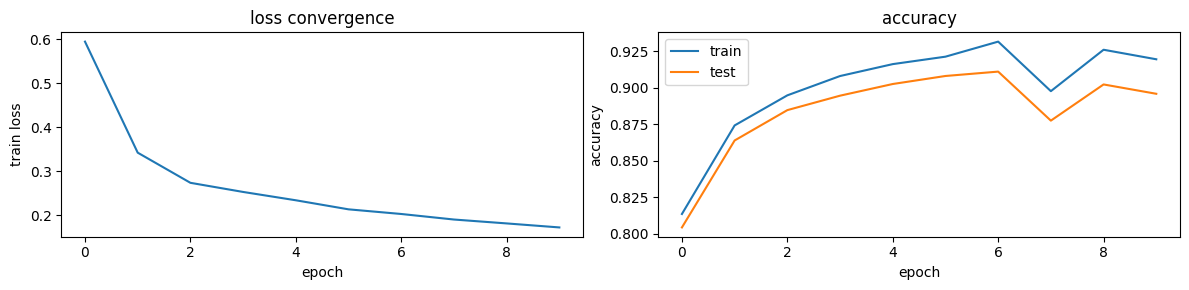

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

def load_data(dir="data/fashion-mnist-torch"):
  train_data = datasets.FashionMNIST(root=dir, train=True, download=True)
  test_data = datasets.FashionMNIST(root=dir, train=False, download=True)
  train_loader = DataLoader(TensorDataset(train_data.data.float().div(255).reshape(-1,1,28,28), train_data.targets), batch_size=256, shuffle=True)
  test_loader = DataLoader(TensorDataset(test_data.data.float().div(255).reshape(-1,1,28,28), test_data.targets), batch_size=256)
  return train_loader, test_loader

def accuracy(loader, net):
  correct = total = 0
  was_training = net.training
  net.eval()
  with torch.no_grad():
    for X,y in loader:
      correct += (net(X).argmax(1)==y).sum().item()
      total += y.numel()
  net.train(was_training)
  return correct/total

class Residual(nn.Module):
  def __init__(self, n_channels, stride=1):
    super().__init__()
    n_in = n_channels if isinstance(n_channels, int) else n_channels[0]
    n_out = n_channels if isinstance(n_channels, int) else n_channels[1]
    self.block = nn.Sequential(nn.Conv2d(n_in, n_out, kernel_size=3, padding=1, stride=stride),
                               nn.BatchNorm2d(n_out),
                               nn.ReLU(),
                               nn.Conv2d(n_out, n_out, kernel_size=3, padding=1),
                               nn.BatchNorm2d(n_out))
    self.conv3 = None if n_in==n_out else nn.Conv2d(n_in, n_out, kernel_size=1, stride=stride)
  def forward(self, X):
    return F.relu(self.block(X) + (self.conv3(X) if self.conv3 else X))

def network(): #mini-ResNet
  net = nn.Sequential(nn.Conv2d(1, 8, kernel_size=3, padding=1), #8x28x28
                      nn.BatchNorm2d(8),
                      nn.ReLU(),
                      Residual(8),
                      Residual(8),
                      Residual((8,16), stride=2), #16x14x14
                      Residual(16),
                      Residual((16,32), stride=2), #32x7x7
                      Residual(32),
                      nn.AdaptiveAvgPool2d((1,1)), #32x1x1
                      nn.Flatten(),
                      nn.Linear(32, 10))
  for m in net.modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
      nn.init.xavier_uniform_(m.weight)
      nn.init.zeros_(m.bias)
  return net

def train(net, train_loader, test_loader, lr=0.1, epochs=10):
  train_losses, train_accs, test_accs = [], [], []
  loss_fn = nn.CrossEntropyLoss()
  trainer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9)
  for epoch in range(epochs):
    total_loss = 0.0
    for X,y in train_loader:
      trainer.zero_grad()
      loss = loss_fn(net(X), y)
      loss.backward()
      trainer.step()
      total_loss += loss.item()
    train_losses.append(total_loss/len(train_loader))
    train_accs.append(accuracy(train_loader, net))
    test_accs.append(accuracy(test_loader, net))
  return train_losses, train_accs, test_accs

train_loader, test_loader = load_data()
train_losses, train_accs, test_accs = train(network(), train_loader, test_loader) #23min, 0.8959
fig, axes = plt.subplots(1, 2, figsize=(12,3))
axes[0].plot(train_losses)
axes[0].set(xlabel="epoch", ylabel="train loss", title="loss convergence")
axes[1].plot(train_accs, label="train")
axes[1].plot(test_accs, label="test")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="accuracy")
axes[1].legend()
fig.tight_layout()
fig.savefig("loss_curve.png", dpi=100)
print(f"test accuracy: {test_accs[-1]:.4f}")

# D2L 9, 10: RNN, LSTM, GRU


**Natural language processing**: Load text with $T$ tokens. Begin each epoch by discarding the first $d$ tokens and partition into $m=⌊(T-d)/n⌋$ subsequences of $n$ tokens.

$\BA
\dg{⇒}&\dg{\t{RNN }}X_t∈ℝ^{n×d}\dg{⇒}H_t=ϕ(X_tW_\t{xh}+H_{t-1}W_\t{hh}+b_\t{h})∈ℝ^{n×h}\dg{⇒}Q_t=H_tW_\t{hq}+b_\t{q}∈ℝ^{n×d}
\EA$


vocab_size=28, parameters=80156

Epoch  10 | train loss 1.7121 (ppl   5.54, acc 0.481) | test loss 1.8961 (ppl   6.66, acc 0.441)
  sample: 'the ashing it immentinas in that reat incelotterouss an'

Epoch  20 | train loss 1.6027 (ppl   4.97, acc 0.512) | test loss 1.8535 (ppl   6.38, acc 0.454)
  sample: 'the meme desigctt still first i in the becuute sente re'

Epoch  30 | train loss 1.5128 (ppl   4.54, acc 0.537) | test loss 1.8625 (ppl   6.44, acc 0.454)
  sample: 'the mething the ematiespe were baren sees cuenibyach ou'

Epoch  40 | train loss 1.4212 (ppl   4.14, acc 0.563) | test loss 1.8759 (ppl   6.53, acc 0.457)
  sample: 'the witlly a lithle geserce matcres forether cound and '

Epoch  50 | train loss 1.3783 (ppl   3.97, acc 0.576) | test loss 1.8846 (ppl   6.58, acc 0.454)
  sample: 'the labe mother sepritation of imaronsword at fell rein'



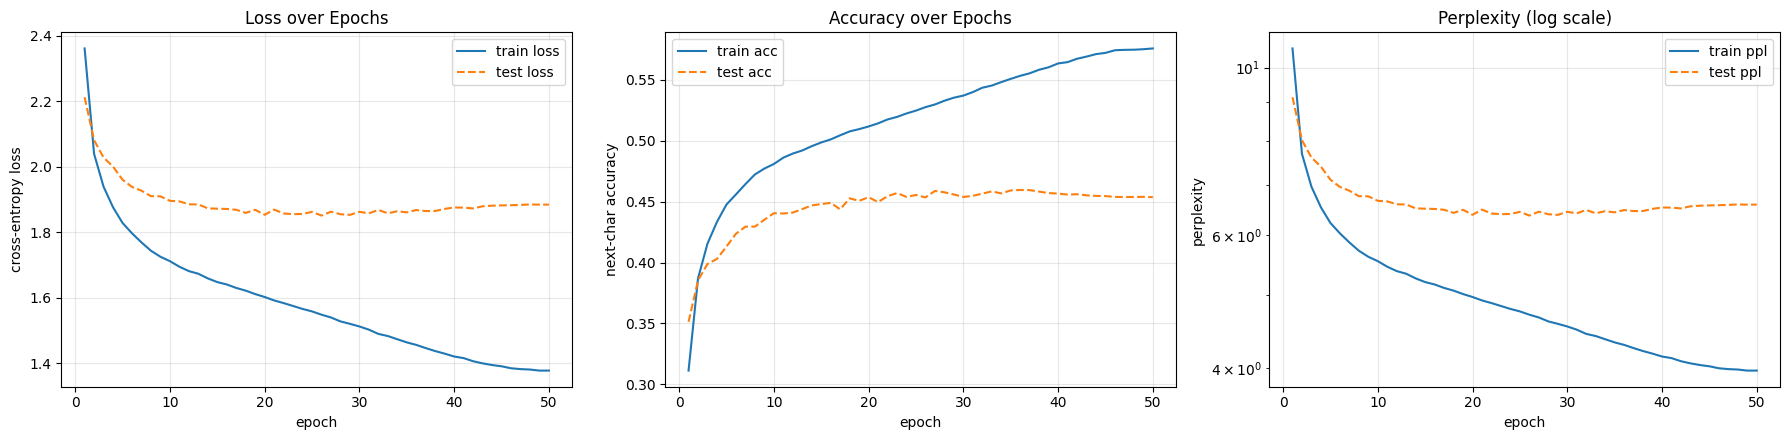

In [ ]:
import requests
import re
import collections
import math
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

class RNN_Model(nn.Module):
  def __init__(self, vocab_size, num_hiddens=256, dropout_p=0.2):
    super().__init__()
    self.num_hiddens, self.vocab_size, bound = num_hiddens, vocab_size, 1/math.sqrt(num_hiddens)
    self.W_xh = nn.Parameter(torch.empty(vocab_size, num_hiddens).uniform_(-bound, bound))
    self.W_hh = nn.Parameter(torch.empty(num_hiddens, num_hiddens))
    nn.init.orthogonal_(self.W_hh)
    self.b_h = nn.Parameter(torch.zeros(num_hiddens))
    self.W_hq = nn.Parameter(torch.empty(num_hiddens, vocab_size).uniform_(-bound, bound))
    self.b_q = nn.Parameter(torch.zeros(vocab_size))
    self.dropout = nn.Dropout(dropout_p)
  def forward(self, inputs, hidden=None):
    hidden = torch.zeros((inputs.shape[0], self.num_hiddens)) if hidden is None else hidden
    inputs_one_hot = F.one_hot(inputs.T, num_classes=self.vocab_size).float()
    all_hiddens = []
    #inputs=(batch_size, num_steps), inputs_one_hot=(num_steps, batch_size, vocab_size)
    #steps: X=(batch_size, vocab_size), X@W_xh=(batch_size, hidden_size), hidden@W_hh=(batch_size, hidden_size)
    for X in inputs_one_hot:
      hidden = torch.tanh(torch.matmul(X, self.W_xh) + torch.matmul(hidden, self.W_hh) + self.b_h) #b.h broadcasting
      all_hiddens.append(hidden)
    all_hiddens = torch.stack(all_hiddens).reshape(-1, self.num_hiddens)
    return torch.matmul(self.dropout(all_hiddens), self.W_hq) + self.b_q, hidden #(num_steps*batch_size, vocab_size)
  def predict(self, prefix, length, vocab):
    output, hidden = [vocab[prefix[0]]], None
    for t in range(len(prefix) + length):
      logits, hidden = self(torch.tensor([[output[-1]]]), hidden)
      output.append(vocab[prefix[t+1]] if t<len(prefix)-1 else torch.multinomial(F.softmax(logits[-1], dim=0), 1).item())
    return ''.join([vocab.idx_to_token[idx] for idx in output])

class Vocab:
  def __init__(self, url="https://www.gutenberg.org/cache/epub/35/pg35.txt", batch_size=64,
               num_steps=32, num_train=15000, num_test=5000):
    self.batch_size, self.num_train, self.num_test, self.num_steps = batch_size, num_train, num_test, num_steps
    r = requests.get(url)
    r.raise_for_status()
    txt = re.sub('[^A-Za-z]+', ' ', r.text.lower())
    txt = txt[txt.find('introduction the time traveller'):]
    self._load_txt(txt)
    self._build_tensors()
  def _load_txt(self, txt, min_freq=1):
    tokens = list(txt)
    tokens_freq = collections.Counter(tokens).items()
    self.idx_to_token = list(set(['<unk>'] + [token for token, freq in tokens_freq if freq>=min_freq]))
    self.token_to_idx = {token:idx for idx, token in enumerate(self.idx_to_token)}
    self.corpus = [self.token_to_idx[token] for token in tokens]
  def __len__(self):
    return len(self.idx_to_token)
  def __getitem__(self, tokens):
    if not isinstance(tokens,(tuple,list)):
      return self.token_to_idx.get(tokens, self.token_to_idx['<unk>'])
    return [self.__getitem__(token) for token in tokens]
  def _build_tensors(self):
    border, stride = int(0.8*len(self.corpus)), self.num_steps // 2
    train_starts = torch.arange(0, border - self.num_steps, stride)
    train_indices = train_starts[torch.randperm(len(train_starts))][:self.num_train]
    test_starts = torch.arange(border, len(self.corpus) - self.num_steps, self.num_steps)
    test_indices = test_starts[:self.num_test]
    self.X_train = torch.tensor([self.corpus[i:i+self.num_steps] for i in train_indices])
    self.Y_train = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in train_indices])
    self.X_test = torch.tensor([self.corpus[i:i+self.num_steps] for i in test_indices])
    self.Y_test = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in test_indices])
  def get_dataloader(self, train=True):  #X.shape,Y.shape=(batch_size, num_steps)
    return DataLoader(TensorDataset(self.X_train, self.Y_train) if train else TensorDataset(self.X_test, self.Y_test),
                      batch_size=self.batch_size, shuffle=train)

def train_epoch(model, data_loader, loss_fn, optimizer, clip_grad=None):
  model.train()
  total_loss, correct, total_tokens = 0.0, 0, 0
  for X,Y in data_loader:
    logits,_ = model(X) # (num_steps * batch_size, vocab_size)
    Y_flat = Y.T.reshape(-1) #(num_steps * batch_size)
    loss = loss_fn(logits, Y_flat)
    optimizer.zero_grad()
    loss.backward()
    if clip_grad is not None:
      torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
    optimizer.step()
    total_loss += loss.item() * Y.numel()
    correct += (logits.argmax(dim=1) == Y_flat).sum().item()
    total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def evaluate(model, data_loader, loss_fn):
  model.eval()
  total_loss, correct, total_tokens = 0.0, 0, 0
  with torch.no_grad():
    for X,Y in data_loader:
      logits,_ = model(X)
      Y_flat = Y.T.reshape(-1)
      loss = loss_fn(logits, Y_flat)
      total_loss += loss.item() * Y.numel()
      correct += (logits.argmax(dim=1) == Y_flat).sum().item()
      total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def train(model, data, num_epochs, lr=0.005, clip_grad=1.0):
  epochs, train_losses, train_accs, test_losses, test_accs = [], [], [], [], []
  loss_fn, optimizer = torch.nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
  for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, data_loader=data.get_dataloader(train=True), loss_fn=loss_fn, optimizer=optimizer, clip_grad=clip_grad)
    test_loss, test_acc = evaluate(model, data_loader=data.get_dataloader(train=False), loss_fn=loss_fn)
    scheduler.step()
    epochs.append(epoch+1)
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)
    if (epoch+1)%10==0:
      with torch.no_grad():
        print(f'Epoch {epoch+1:3d} | '
              f'train loss {train_loss:.4f} (ppl {math.exp(train_loss):6.2f}, acc {train_acc:.3f}) | '
              f'test loss {test_loss:.4f} (ppl {math.exp(test_loss):6.2f}, acc {test_acc:.3f})\n'
              f'  sample: {repr(model.predict('the ', 50, data))}\n')
  return epochs, train_losses, train_accs, test_losses, test_accs

def plot_results(epochs, train_losses, train_accs, test_losses, test_accs,
                 save_path='rnn_training_curves.png'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].plot(epochs, train_losses, label='train loss')
    axes[0].plot(epochs, test_losses, label='test loss', linestyle='--')
    axes[0].set(xlabel='epoch', ylabel='cross-entropy loss', title='Loss over Epochs')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, train_accs, label='train acc')
    axes[1].plot(epochs, test_accs, label='test acc', linestyle='--')
    axes[1].set(xlabel='epoch', ylabel='next-char accuracy', title='Accuracy over Epochs')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    axes[2].plot(epochs, [math.exp(l) for l in train_losses], label='train ppl')
    axes[2].plot(epochs, [math.exp(l) for l in test_losses], label='test ppl', linestyle='--')
    axes[2].set(xlabel='epoch', ylabel='perplexity', title='Perplexity (log scale)')
    axes[2].set_yscale('log')
    axes[2].legend()
    axes[2].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_path, dpi=100)
    plt.show()

data = Vocab()
model = RNN_Model(vocab_size=len(data))
print(f'vocab_size={len(data)}, parameters={sum(p.numel() for p in model.parameters())}\n')
epochs, train_losses, train_accs, test_losses, test_accs = train(model, data, num_epochs=50)
plot_results(epochs, train_losses, train_accs, test_losses, test_accs)

- **nn.RNN and nn.Embedding**: `nn.Embedding` uses a more 256×256 dense embedding instead of $d$×256 sparse one-hot embedding to drop perplexity from 6.4 to 5.6.

vocab_size=28, parameters=145948

Epoch  10 | train loss 1.5060 (ppl   4.51, acc 0.537) | test loss 1.7492 (ppl   5.75, acc 0.479)
  sample: 'the hillsed the greees for exich crevellers who had ove'

Epoch  20 | train loss 1.4454 (ppl   4.24, acc 0.556) | test loss 1.7378 (ppl   5.69, acc 0.483)
  sample: 'the denory on last phaking smilived shayed hims the bla'

Epoch  30 | train loss 1.3806 (ppl   3.98, acc 0.574) | test loss 1.7372 (ppl   5.68, acc 0.484)
  sample: 'the shatcred incensactions with his wand the barorated '

Epoch  40 | train loss 1.3144 (ppl   3.72, acc 0.594) | test loss 1.7422 (ppl   5.71, acc 0.488)
  sample: 'the whi had with interrocanal better that it was alread'

Epoch  50 | train loss 1.2816 (ppl   3.60, acc 0.605) | test loss 1.7489 (ppl   5.75, acc 0.487)
  sample: 'the narrooss bup as though the absolucy a porkelace s i'



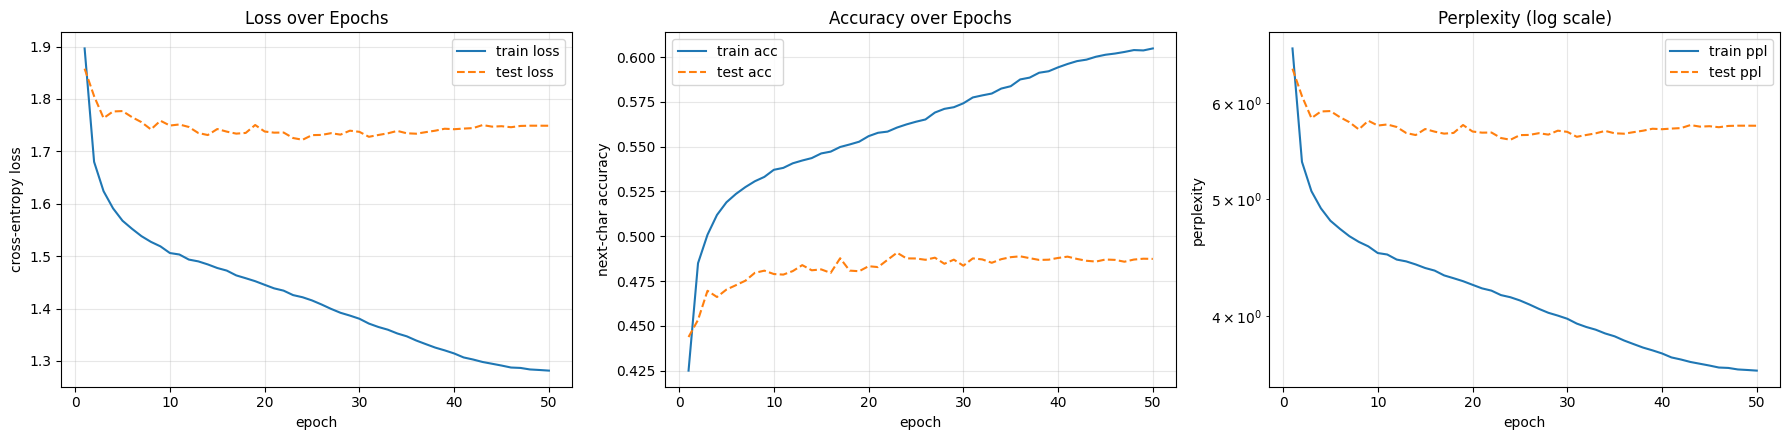

In [ ]:
import requests
import re
import collections
import math
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

class RNN_Model(nn.Module): #only difference from the raw implementation
  def __init__(self, vocab_size, num_hiddens=256, dropout_p=0.2):
    super().__init__()
    self.num_hiddens, self.vocab_size = num_hiddens, vocab_size
    self.embedding = nn.Embedding(vocab_size, num_hiddens)
    self.rnn = nn.RNN(input_size=num_hiddens, hidden_size=num_hiddens, num_layers=1, batch_first=False, dropout=0)
    self.dropout = nn.Dropout(dropout_p)
    self.fc = nn.Linear(num_hiddens, vocab_size)
  def forward(self, inputs, hidden=None):
    outputs, hidden = self.rnn(self.embedding(inputs.T), hidden)
    return self.fc(self.dropout(outputs.reshape(-1, self.num_hiddens))), hidden
  def predict(self, prefix, length, vocab):
    output, hidden = [vocab[prefix[0]]], None
    for t in range(len(prefix) + length):
      logits, hidden = self(torch.tensor([[output[-1]]]), hidden)
      output.append(vocab[prefix[t+1]] if t<len(prefix)-1 else torch.multinomial(F.softmax(logits[-1], dim=0), 1).item())
    return ''.join([vocab.idx_to_token[idx] for idx in output])

class Vocab:
  def __init__(self, url="https://www.gutenberg.org/cache/epub/35/pg35.txt", batch_size=64,
               num_steps=32, num_train=15000, num_test=5000):
    self.batch_size, self.num_train, self.num_test, self.num_steps = batch_size, num_train, num_test, num_steps
    r = requests.get(url)
    r.raise_for_status()
    txt = re.sub('[^A-Za-z]+', ' ', r.text.lower())
    txt = txt[txt.find('introduction the time traveller'):]
    self._load_txt(txt)
    self._build_tensors()
  def _load_txt(self, txt, min_freq=1):
    tokens = list(txt)
    tokens_freq = collections.Counter(tokens).items()
    self.idx_to_token = list(set(['<unk>'] + [token for token, freq in tokens_freq if freq>=min_freq]))
    self.token_to_idx = {token:idx for idx, token in enumerate(self.idx_to_token)}
    self.corpus = [self.token_to_idx[token] for token in tokens]
  def __len__(self):
    return len(self.idx_to_token)
  def __getitem__(self, tokens):
    if not isinstance(tokens,(tuple,list)):
      return self.token_to_idx.get(tokens, self.token_to_idx['<unk>'])
    return [self.__getitem__(token) for token in tokens]
  def _build_tensors(self):
    border, stride = int(0.8*len(self.corpus)), self.num_steps // 2
    train_starts = torch.arange(0, border - self.num_steps, stride)
    train_indices = train_starts[torch.randperm(len(train_starts))][:self.num_train]
    test_starts = torch.arange(border, len(self.corpus) - self.num_steps, self.num_steps)
    test_indices = test_starts[:self.num_test]
    self.X_train = torch.tensor([self.corpus[i:i+self.num_steps] for i in train_indices])
    self.Y_train = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in train_indices])
    self.X_test = torch.tensor([self.corpus[i:i+self.num_steps] for i in test_indices])
    self.Y_test = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in test_indices])
  def get_dataloader(self, train=True):  #X.shape,Y.shape=(batch_size, num_steps)
    return DataLoader(TensorDataset(self.X_train, self.Y_train) if train else TensorDataset(self.X_test, self.Y_test),
                      batch_size=self.batch_size, shuffle=train)

def train_epoch(model, data_loader, loss_fn, optimizer, clip_grad=None):
  model.train()
  total_loss, correct, total_tokens = 0.0, 0, 0
  for X,Y in data_loader:
    logits,_ = model(X) # (num_steps * batch_size, vocab_size)
    Y_flat = Y.T.reshape(-1) #(num_steps * batch_size)
    loss = loss_fn(logits, Y_flat)
    optimizer.zero_grad()
    loss.backward()
    if clip_grad is not None:
      torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
    optimizer.step()
    total_loss += loss.item() * Y.numel()
    correct += (logits.argmax(dim=1) == Y_flat).sum().item()
    total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def evaluate(model, data_loader, loss_fn):
  model.eval()
  total_loss, correct, total_tokens = 0.0, 0, 0
  with torch.no_grad():
    for X,Y in data_loader:
      logits,_ = model(X)
      Y_flat = Y.T.reshape(-1)
      loss = loss_fn(logits, Y_flat)
      total_loss += loss.item() * Y.numel()
      correct += (logits.argmax(dim=1) == Y_flat).sum().item()
      total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def train(model, data, num_epochs, lr=0.005, clip_grad=1.0):
  epochs, train_losses, train_accs, test_losses, test_accs = [], [], [], [], []
  loss_fn, optimizer = torch.nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
  for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, data_loader=data.get_dataloader(train=True), loss_fn=loss_fn, optimizer=optimizer, clip_grad=clip_grad)
    test_loss, test_acc = evaluate(model, data_loader=data.get_dataloader(train=False), loss_fn=loss_fn)
    scheduler.step()
    epochs.append(epoch+1)
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)
    if (epoch+1)%10==0:
      with torch.no_grad():
        print(f'Epoch {epoch+1:3d} | '
              f'train loss {train_loss:.4f} (ppl {math.exp(train_loss):6.2f}, acc {train_acc:.3f}) | '
              f'test loss {test_loss:.4f} (ppl {math.exp(test_loss):6.2f}, acc {test_acc:.3f})\n'
              f'  sample: {repr(model.predict('the ', 50, data))}\n')
  return epochs, train_losses, train_accs, test_losses, test_accs

def plot_results(epochs, train_losses, train_accs, test_losses, test_accs,
                 save_path='rnn_training_curves.png'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].plot(epochs, train_losses, label='train loss')
    axes[0].plot(epochs, test_losses, label='test loss', linestyle='--')
    axes[0].set(xlabel='epoch', ylabel='cross-entropy loss', title='Loss over Epochs')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, train_accs, label='train acc')
    axes[1].plot(epochs, test_accs, label='test acc', linestyle='--')
    axes[1].set(xlabel='epoch', ylabel='next-char accuracy', title='Accuracy over Epochs')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    axes[2].plot(epochs, [math.exp(l) for l in train_losses], label='train ppl')
    axes[2].plot(epochs, [math.exp(l) for l in test_losses], label='test ppl', linestyle='--')
    axes[2].set(xlabel='epoch', ylabel='perplexity', title='Perplexity (log scale)')
    axes[2].set_yscale('log')
    axes[2].legend()
    axes[2].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_path, dpi=100)
    plt.show()

data = Vocab()
model = RNN_Model(vocab_size=len(data))
print(f'vocab_size={len(data)}, parameters={sum(p.numel() for p in model.parameters())}\n')
epochs, train_losses, train_accs, test_losses, test_accs = train(model, data, num_epochs=50)
plot_results(epochs, train_losses, train_accs, test_losses, test_accs)

- **LSTM**: only difference with RNN is in `RNN.__init__` and `RNN.forward`. Parameter size is much larger for 256 hidden units, and requires larger training corpus to prevent over-fitting.

$\BA
\dg{⇒}&\BC
\dg{\t{input gate }}I_t=σ(X_tW_{xi}+H_{t-1}W_{hi}+b_i)∈ℝ^{n×h}&
\dg{\t{forget gate }}F_t=σ(X_tW_{xf}+H_{t-1}W_{hf}+b_f)∈ℝ^{n×h}\\
\dg{\t{output gate }}O_t=σ(X_tW_{xo}+H_{t-1}W_{ho}+b_o)∈ℝ^{n×h}&
\dg{\t{candidate }}\tilde{C}_t=\tanh(X_tW_{xc}+H_{t-1}W_{hc}+b_c)∈ℝ^{n×h}\\
\dg{\t{update cell }}C_t=F_t⊙C_{t-1}+I_t⊙\tilde{C}_t∈ℝ^{n×h}&\dg{\t{hidden }}H_t=O_t⊙\tanh(C_t)∈ℝ^{n×h}\\
\dg{\t{input }}X_t∈ℝ^{n×d}\dg{⇒\t{output }}Q_t=H_tW_\t{hq}+b_\t{q}∈ℝ^{n×d}
\EC\\
\EA$

vocab_size=28, parameters=299036

Epoch  10 | train loss 1.8937 (ppl   6.64, acc 0.424) | test loss 1.8372 (ppl   6.28, acc 0.450)
  sample: 'the pllgatlit le stringe pdy bownning for abont i smoug'

Epoch  20 | train loss 1.8168 (ppl   6.15, acc 0.445) | test loss 1.7924 (ppl   6.00, acc 0.462)
  sample: 'the expention of the porrortal of him foon out of the r'

Epoch  30 | train loss 1.7733 (ppl   5.89, acc 0.459) | test loss 1.7757 (ppl   5.90, acc 0.464)
  sample: 'the nownofreed corill at os their expsyeation llesh the'

Epoch  40 | train loss 1.7368 (ppl   5.68, acc 0.468) | test loss 1.7683 (ppl   5.86, acc 0.470)
  sample: 'the perhaps an of the rigmstine of the mere incasted an'

Epoch  50 | train loss 1.7138 (ppl   5.55, acc 0.475) | test loss 1.7703 (ppl   5.87, acc 0.468)
  sample: 'the bermanism the bir that shider thingsithe langand ex'



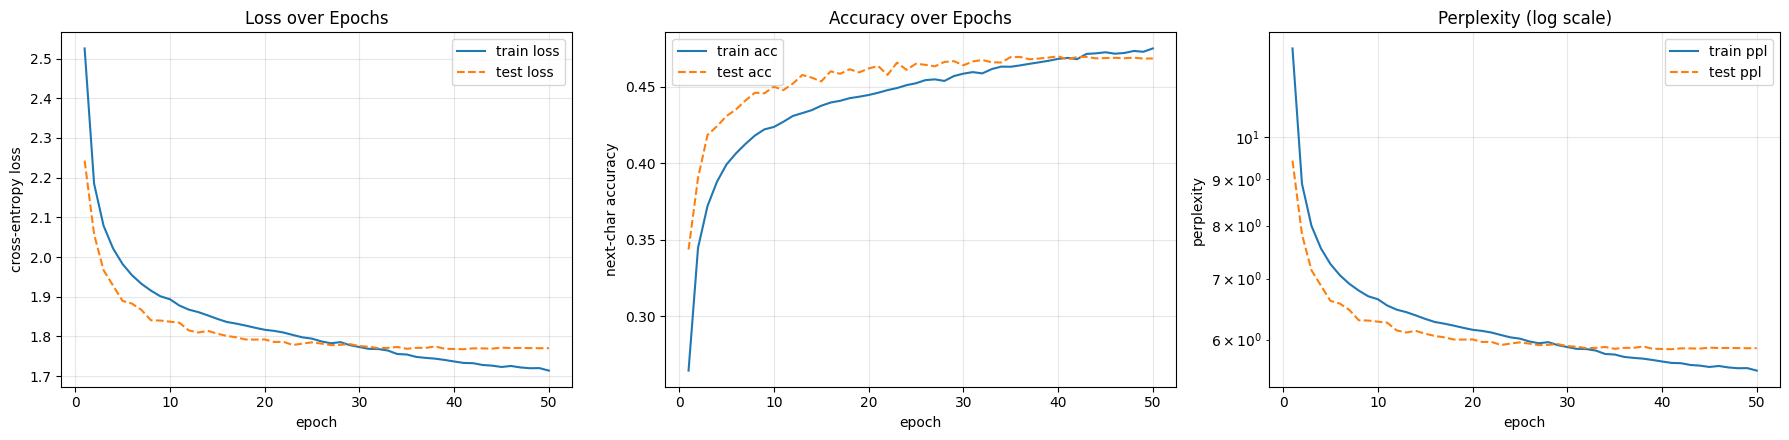

In [ ]:
import requests
import re
import collections
import math
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

class LSTM_Model(nn.Module):
  def __init__(self, vocab_size, num_hiddens=256, dropout_p=0.2):
    super().__init__()
    self.num_hiddens, self.vocab_size, bound = num_hiddens, vocab_size, 1/math.sqrt(num_hiddens)
    uniform_xh = lambda:nn.Parameter(torch.empty(vocab_size, num_hiddens).uniform_(-bound,bound))
    def orthogonal_hh():
      param = nn.Parameter(torch.empty(num_hiddens, num_hiddens))
      nn.init.orthogonal_(param)
      return param
    three = lambda:(uniform_xh(), orthogonal_hh(), nn.Parameter(torch.zeros(num_hiddens)))
    self.W_xi, self.W_hi, self.b_i=three()
    self.W_xo, self.W_ho, self.b_o=three()
    self.W_xc, self.W_hc, self.b_c=three()
    self.W_xf, self.W_hf, _=three()
    self.b_f = nn.Parameter(torch.ones(num_hiddens))
    self.W_hq = nn.Parameter(torch.empty(num_hiddens, vocab_size).uniform_(-bound, bound))
    self.b_q = nn.Parameter(torch.zeros(vocab_size))
    self.dropout_in, self.dropout_out = nn.Dropout(dropout_p), nn.Dropout(dropout_p)
  def forward(self, inputs, H_C=None): #inputs=(batch_size, num_steps)
    H, C = H_C if H_C is not None else (torch.zeros((inputs.shape[0], self.num_hiddens)), torch.zeros((inputs.shape[0], self.num_hiddens)))
    inputs_one_hot, hiddens = F.one_hot(inputs.T, self.vocab_size).float(), []
    for X in self.dropout_in(inputs_one_hot): #X=(batch_size, vocab_size)
      I_gate = torch.sigmoid(torch.matmul(X, self.W_xi) + torch.matmul(H, self.W_hi) + self.b_i)
      F_gate = torch.sigmoid(torch.matmul(X, self.W_xf) + torch.matmul(H, self.W_hf) + self.b_f)
      O_gate = torch.sigmoid(torch.matmul(X, self.W_xo) + torch.matmul(H, self.W_ho) + self.b_o)
      C_tilde = torch.tanh(torch.matmul(X, self.W_xc) + torch.matmul(H, self.W_hc) + self.b_c)
      C = F_gate * C + I_gate * C_tilde
      H = O_gate * torch.tanh(C)
      hiddens.append(H)
    hiddens = torch.stack(hiddens).reshape(-1, self.num_hiddens)
    return torch.matmul(self.dropout_out(hiddens), self.W_hq) + self.b_q, (H,C)
  def predict(self, prefix, length, vocab):
    output, hidden = [vocab[prefix[0]]], None
    for t in range(len(prefix) + length):
      logits, hidden = self(torch.tensor([[output[-1]]]), hidden)
      output.append(vocab[prefix[t+1]] if t<len(prefix)-1 else torch.multinomial(F.softmax(logits[-1], dim=0), 1).item())
    return ''.join([vocab.idx_to_token[idx] for idx in output])

class Vocab:
  def __init__(self, url="https://www.gutenberg.org/cache/epub/35/pg35.txt", batch_size=64,
               num_steps=32, num_train=15000, num_test=5000):
    self.batch_size, self.num_train, self.num_test, self.num_steps = batch_size, num_train, num_test, num_steps
    r = requests.get(url)
    r.raise_for_status()
    txt = re.sub('[^A-Za-z]+', ' ', r.text.lower())
    txt = txt[txt.find('introduction the time traveller'):]
    self._load_txt(txt)
    self._build_tensors()
  def _load_txt(self, txt, min_freq=1):
    tokens = list(txt)
    tokens_freq = collections.Counter(tokens).items()
    self.idx_to_token = sorted(set(['<unk>'] + [token for token, freq in tokens_freq if freq>=min_freq]))
    self.token_to_idx = {token:idx for idx, token in enumerate(self.idx_to_token)}
    self.corpus = [self.token_to_idx[token] for token in tokens]
  def __len__(self):
    return len(self.idx_to_token)
  def __getitem__(self, tokens):
    if not isinstance(tokens,(tuple,list)):
      return self.token_to_idx.get(tokens, self.token_to_idx['<unk>'])
    return [self.__getitem__(token) for token in tokens]
  def _build_tensors(self):
    border, stride = int(0.8*len(self.corpus)), self.num_steps // 2
    train_starts = torch.arange(0, border - self.num_steps, stride)
    train_indices = train_starts[torch.randperm(len(train_starts))][:self.num_train]
    test_starts = torch.arange(border, len(self.corpus) - self.num_steps, self.num_steps)
    test_indices = test_starts[:self.num_test]
    self.X_train = torch.tensor([self.corpus[i:i+self.num_steps] for i in train_indices])
    self.Y_train = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in train_indices])
    self.X_test = torch.tensor([self.corpus[i:i+self.num_steps] for i in test_indices])
    self.Y_test = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in test_indices])
  def get_dataloader(self, train=True):  #X.shape,Y.shape=(batch_size, num_steps)
    return DataLoader(TensorDataset(self.X_train, self.Y_train) if train else TensorDataset(self.X_test, self.Y_test),
                      batch_size=self.batch_size, shuffle=train)

def train_epoch(model, data_loader, loss_fn, optimizer, clip_grad=None):
  model.train()
  total_loss, correct, total_tokens = 0.0, 0, 0
  for X,Y in data_loader:
    logits,_ = model(X) # (num_steps * batch_size, vocab_size)
    Y_flat = Y.T.reshape(-1) #(num_steps * batch_size)
    loss = loss_fn(logits, Y_flat)
    optimizer.zero_grad()
    loss.backward()
    if clip_grad is not None:
      torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
    optimizer.step()
    total_loss += loss.item() * Y.numel()
    correct += (logits.argmax(dim=1) == Y_flat).sum().item()
    total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def evaluate(model, data_loader, loss_fn):
  model.eval()
  total_loss, correct, total_tokens = 0.0, 0, 0
  with torch.no_grad():
    for X,Y in data_loader:
      logits,_ = model(X)
      Y_flat = Y.T.reshape(-1)
      loss = loss_fn(logits, Y_flat)
      total_loss += loss.item() * Y.numel()
      correct += (logits.argmax(dim=1) == Y_flat).sum().item()
      total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def train(model, data, num_epochs, lr=0.005, clip_grad=1.0):
  epochs, train_losses, train_accs, test_losses, test_accs = [], [], [], [], []
  loss_fn, optimizer = torch.nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
  for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, data_loader=data.get_dataloader(train=True), loss_fn=loss_fn, optimizer=optimizer, clip_grad=clip_grad)
    test_loss, test_acc = evaluate(model, data_loader=data.get_dataloader(train=False), loss_fn=loss_fn)
    scheduler.step()
    epochs.append(epoch+1)
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)
    if (epoch+1)%10==0:
      with torch.no_grad():
        print(f'Epoch {epoch+1:3d} | '
              f'train loss {train_loss:.4f} (ppl {math.exp(train_loss):6.2f}, acc {train_acc:.3f}) | '
              f'test loss {test_loss:.4f} (ppl {math.exp(test_loss):6.2f}, acc {test_acc:.3f})\n'
              f'  sample: {repr(model.predict('the ', 50, data))}\n')
  return epochs, train_losses, train_accs, test_losses, test_accs

def plot_results(epochs, train_losses, train_accs, test_losses, test_accs,
                 save_path='rnn_training_curves.png'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].plot(epochs, train_losses, label='train loss')
    axes[0].plot(epochs, test_losses, label='test loss', linestyle='--')
    axes[0].set(xlabel='epoch', ylabel='cross-entropy loss', title='Loss over Epochs')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, train_accs, label='train acc')
    axes[1].plot(epochs, test_accs, label='test acc', linestyle='--')
    axes[1].set(xlabel='epoch', ylabel='next-char accuracy', title='Accuracy over Epochs')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    axes[2].plot(epochs, [math.exp(l) for l in train_losses], label='train ppl')
    axes[2].plot(epochs, [math.exp(l) for l in test_losses], label='test ppl', linestyle='--')
    axes[2].set(xlabel='epoch', ylabel='perplexity', title='Perplexity (log scale)')
    axes[2].set_yscale('log')
    axes[2].legend()
    axes[2].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_path, dpi=100)
    plt.show()

data = Vocab()
model = LSTM_Model(vocab_size=len(data))
print(f'vocab_size={len(data)}, parameters={sum(p.numel() for p in model.parameters())}\n')
epochs, train_losses, train_accs, test_losses, test_accs = train(model, data, num_epochs=50)
plot_results(epochs, train_losses, train_accs, test_losses, test_accs)

vocab_size=28, parameters=540700

Epoch  10 | train loss 1.3803 (ppl   3.98, acc 0.567) | test loss 1.7013 (ppl   5.48, acc 0.492)
  sample: 'the thew robe me to me that stect that burldifnest tant'

Epoch  20 | train loss 1.3038 (ppl   3.68, acc 0.589) | test loss 1.6851 (ppl   5.39, acc 0.502)
  sample: 'the bright pights stilk in and feforiency imperpeting g'

Epoch  30 | train loss 1.2217 (ppl   3.39, acc 0.613) | test loss 1.6999 (ppl   5.47, acc 0.503)
  sample: 'the fruits in his gales breakhed out and weena galled o'

Epoch  40 | train loss 1.1390 (ppl   3.12, acc 0.638) | test loss 1.7439 (ppl   5.72, acc 0.502)
  sample: 'the lamp as of strembly from the levers from her habjes'

Epoch  50 | train loss 1.1005 (ppl   3.01, acc 0.652) | test loss 1.7559 (ppl   5.79, acc 0.500)
  sample: 'the queer sbreatchet but the time machine i have come u'



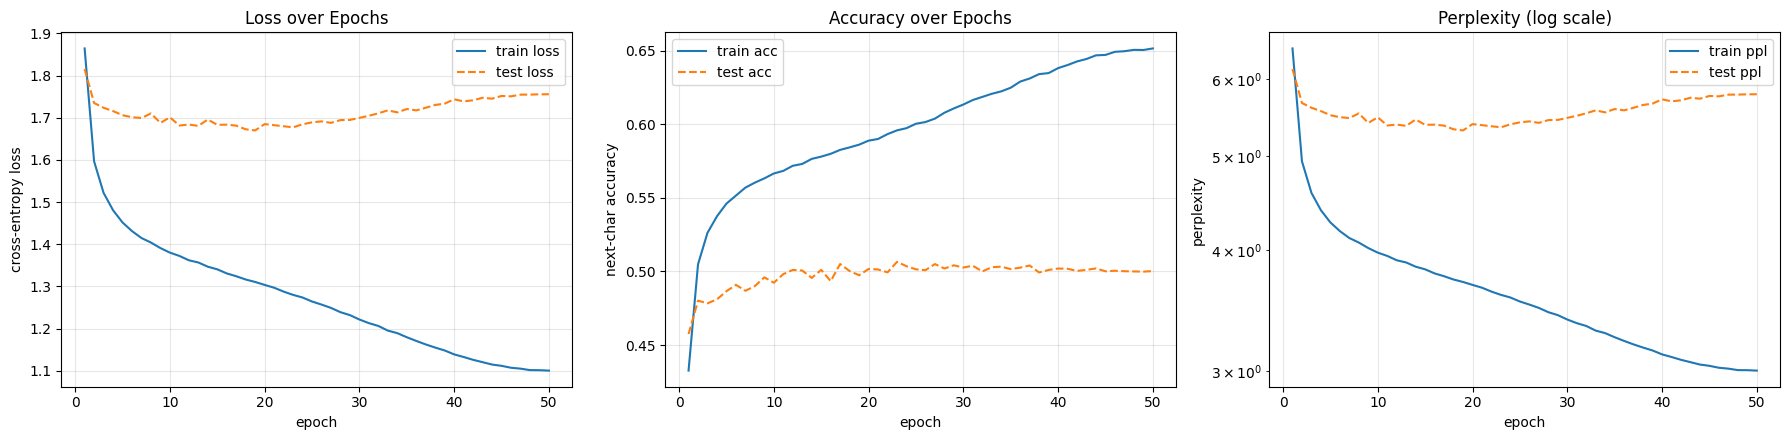

In [ ]:
import requests
import re
import collections
import math
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

class LSTM_Model(nn.Module):
  def __init__(self, vocab_size, num_hiddens=256, dropout_p=0.2):
    super().__init__()
    self.num_hiddens, self.vocab_size = num_hiddens, vocab_size
    self.embedding, self.dropout_in, self.dropout_out = nn.Embedding(vocab_size, num_hiddens), nn.Dropout(dropout_p), nn.Dropout(dropout_p)
    self.lstm = nn.LSTM(input_size=num_hiddens, hidden_size=num_hiddens, num_layers=1, batch_first=False, dropout=0)
    self.fc = nn.Linear(num_hiddens, vocab_size)
  def forward(self, inputs, H_C=None): #inputs=(batch_size, num_steps)
    hiddens, H_C = self.lstm(self.dropout_in(self.embedding(inputs.T)), H_C)
    return self.fc(self.dropout_out(hiddens).reshape(-1, self.num_hiddens)), H_C
  def predict(self, prefix, length, vocab):
    output, hidden = [vocab[prefix[0]]], None
    for t in range(len(prefix) + length):
      logits, hidden = self(torch.tensor([[output[-1]]]), hidden)
      output.append(vocab[prefix[t+1]] if t<len(prefix)-1 else torch.multinomial(F.softmax(logits[-1], dim=0), 1).item())
    return ''.join([vocab.idx_to_token[idx] for idx in output])

class Vocab:
  def __init__(self, url="https://www.gutenberg.org/cache/epub/35/pg35.txt", batch_size=64,
               num_steps=32, num_train=15000, num_test=5000):
    self.batch_size, self.num_train, self.num_test, self.num_steps = batch_size, num_train, num_test, num_steps
    r = requests.get(url)
    r.raise_for_status()
    txt = re.sub('[^A-Za-z]+', ' ', r.text.lower())
    txt = txt[txt.find('introduction the time traveller'):]
    self._load_txt(txt)
    self._build_tensors()
  def _load_txt(self, txt, min_freq=1):
    tokens = list(txt)
    tokens_freq = collections.Counter(tokens).items()
    self.idx_to_token = sorted(set(['<unk>'] + [token for token, freq in tokens_freq if freq>=min_freq]))
    self.token_to_idx = {token:idx for idx, token in enumerate(self.idx_to_token)}
    self.corpus = [self.token_to_idx[token] for token in tokens]
  def __len__(self):
    return len(self.idx_to_token)
  def __getitem__(self, tokens):
    if not isinstance(tokens,(tuple,list)):
      return self.token_to_idx.get(tokens, self.token_to_idx['<unk>'])
    return [self.__getitem__(token) for token in tokens]
  def _build_tensors(self):
    border, stride = int(0.8*len(self.corpus)), self.num_steps // 2
    train_starts = torch.arange(0, border - self.num_steps, stride)
    train_indices = train_starts[torch.randperm(len(train_starts))][:self.num_train]
    test_starts = torch.arange(border, len(self.corpus) - self.num_steps, self.num_steps)
    test_indices = test_starts[:self.num_test]
    self.X_train = torch.tensor([self.corpus[i:i+self.num_steps] for i in train_indices])
    self.Y_train = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in train_indices])
    self.X_test = torch.tensor([self.corpus[i:i+self.num_steps] for i in test_indices])
    self.Y_test = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in test_indices])
  def get_dataloader(self, train=True):  #X.shape,Y.shape=(batch_size, num_steps)
    return DataLoader(TensorDataset(self.X_train, self.Y_train) if train else TensorDataset(self.X_test, self.Y_test),
                      batch_size=self.batch_size, shuffle=train)

def train_epoch(model, data_loader, loss_fn, optimizer, clip_grad=None):
  model.train()
  total_loss, correct, total_tokens = 0.0, 0, 0
  for X,Y in data_loader:
    logits,_ = model(X) # (num_steps * batch_size, vocab_size)
    Y_flat = Y.T.reshape(-1) #(num_steps * batch_size)
    loss = loss_fn(logits, Y_flat)
    optimizer.zero_grad()
    loss.backward()
    if clip_grad is not None:
      torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
    optimizer.step()
    total_loss += loss.item() * Y.numel()
    correct += (logits.argmax(dim=1) == Y_flat).sum().item()
    total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def evaluate(model, data_loader, loss_fn):
  model.eval()
  total_loss, correct, total_tokens = 0.0, 0, 0
  with torch.no_grad():
    for X,Y in data_loader:
      logits,_ = model(X)
      Y_flat = Y.T.reshape(-1)
      loss = loss_fn(logits, Y_flat)
      total_loss += loss.item() * Y.numel()
      correct += (logits.argmax(dim=1) == Y_flat).sum().item()
      total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def train(model, data, num_epochs, lr=0.005, clip_grad=1.0):
  epochs, train_losses, train_accs, test_losses, test_accs = [], [], [], [], []
  loss_fn, optimizer = torch.nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
  for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, data_loader=data.get_dataloader(train=True), loss_fn=loss_fn, optimizer=optimizer, clip_grad=clip_grad)
    test_loss, test_acc = evaluate(model, data_loader=data.get_dataloader(train=False), loss_fn=loss_fn)
    scheduler.step()
    epochs.append(epoch+1)
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)
    if (epoch+1)%10==0:
      with torch.no_grad():
        print(f'Epoch {epoch+1:3d} | '
              f'train loss {train_loss:.4f} (ppl {math.exp(train_loss):6.2f}, acc {train_acc:.3f}) | '
              f'test loss {test_loss:.4f} (ppl {math.exp(test_loss):6.2f}, acc {test_acc:.3f})\n'
              f'  sample: {repr(model.predict('the ', 50, data))}\n')
  return epochs, train_losses, train_accs, test_losses, test_accs

def plot_results(epochs, train_losses, train_accs, test_losses, test_accs,
                 save_path='rnn_training_curves.png'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].plot(epochs, train_losses, label='train loss')
    axes[0].plot(epochs, test_losses, label='test loss', linestyle='--')
    axes[0].set(xlabel='epoch', ylabel='cross-entropy loss', title='Loss over Epochs')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, train_accs, label='train acc')
    axes[1].plot(epochs, test_accs, label='test acc', linestyle='--')
    axes[1].set(xlabel='epoch', ylabel='next-char accuracy', title='Accuracy over Epochs')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    axes[2].plot(epochs, [math.exp(l) for l in train_losses], label='train ppl')
    axes[2].plot(epochs, [math.exp(l) for l in test_losses], label='test ppl', linestyle='--')
    axes[2].set(xlabel='epoch', ylabel='perplexity', title='Perplexity (log scale)')
    axes[2].set_yscale('log')
    axes[2].legend()
    axes[2].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_path, dpi=100)
    plt.show()

data = Vocab()
model = LSTM_Model(vocab_size=len(data))
print(f'vocab_size={len(data)}, parameters={sum(p.numel() for p in model.parameters())}\n')
epochs, train_losses, train_accs, test_losses, test_accs = train(model, data, num_epochs=50)
plot_results(epochs, train_losses, train_accs, test_losses, test_accs)

- **GRU**: slightly more parameters-efficient than LSTM.

$\BA
\dg{⇒}&\BC
\dg{\t{reset gate }}R_t=σ(X_tW_{xr}+H_{t-1}W_{hr}+b_r)∈ℝ^{n×h}&
\dg{\t{update gate }}Z_t=σ(X_tW_{xz}+H_{t-1}W_{hz}+b_z)∈ℝ^{n×h}\\
\dg{\t{candidate }}\tilde{H}_t=\tanh(X_tW_{xh}+(R_t⊙H_{t-1})W_{hh}+b_h)&\dg{\t{update hidden }}H_t=Z_t⊙H_{t-1}+(1-Z_t)⊙\tilde{H}_t\\
\dg{\t{input }}X_t∈ℝ^{n×d}\dg{⇒\t{output }}Q_t=H_tW_\t{hq}+b_\t{q}∈ℝ^{n×d}
\EC\\
\EA$

vocab_size=28, parameters=226076

Epoch  10 | train loss 1.8091 (ppl   6.10, acc 0.448) | test loss 1.8108 (ppl   6.12, acc 0.457)
  sample: 'the mortowoslessed the doovert would be anctimat tiee a'

Epoch  20 | train loss 1.7273 (ppl   5.63, acc 0.469) | test loss 1.7743 (ppl   5.90, acc 0.469)
  sample: 'the hriundep were any perelwsh s nalarious pplongation '

Epoch  30 | train loss 1.6673 (ppl   5.30, acc 0.486) | test loss 1.7615 (ppl   5.82, acc 0.477)
  sample: 'the daheness aod ran and in an anternated nee s me loot'

Epoch  40 | train loss 1.6169 (ppl   5.04, acc 0.500) | test loss 1.7538 (ppl   5.78, acc 0.479)
  sample: 'the trauempe toyether laye whei went on upperfasl whona'

Epoch  50 | train loss 1.5893 (ppl   4.90, acc 0.509) | test loss 1.7575 (ppl   5.80, acc 0.479)
  sample: 'the eddlymparta if hove seel i hade pepple some ungim l'



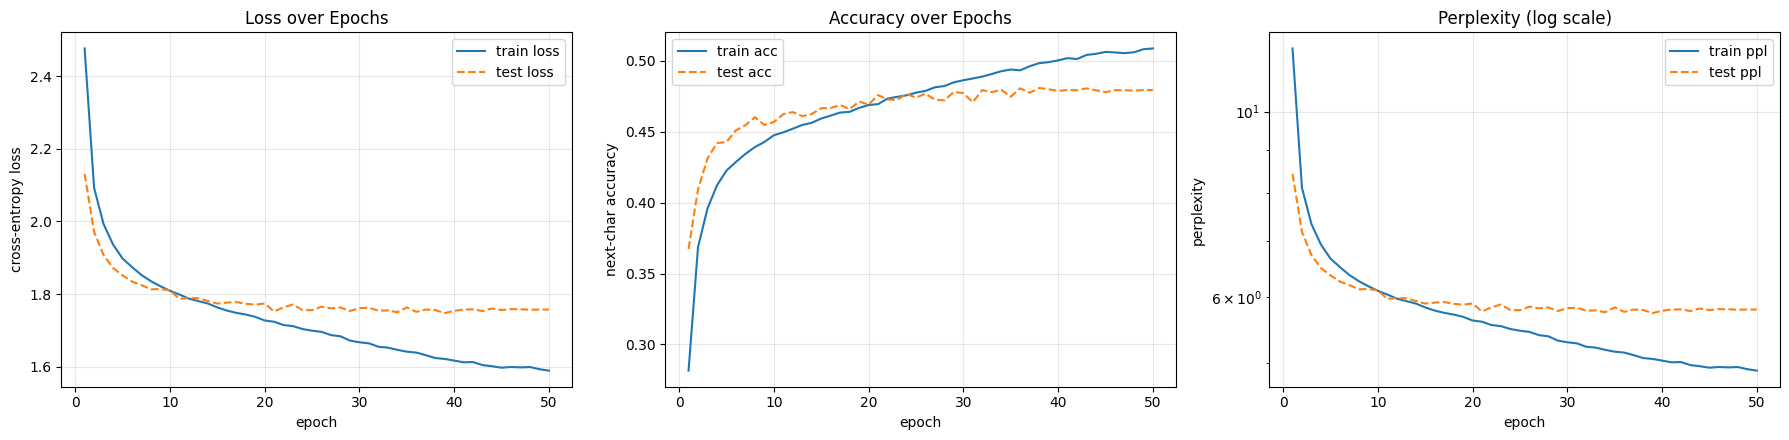

In [ ]:
import requests
import re
import collections
import math
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

class GRU_Model(nn.Module):
  def __init__(self, vocab_size, num_hiddens=256, dropout_p=0.2):
    super().__init__()
    self.num_hiddens, self.vocab_size, bound = num_hiddens, vocab_size, 1/math.sqrt(num_hiddens)
    uniform_xh = lambda:nn.Parameter(torch.empty(vocab_size, num_hiddens).uniform_(-bound,bound))
    def orthogonal_hh():
      param = nn.Parameter(torch.empty(num_hiddens, num_hiddens))
      nn.init.orthogonal_(param)
      return param
    three = lambda:(uniform_xh(), orthogonal_hh(), nn.Parameter(torch.zeros(num_hiddens)))
    self.W_xr, self.W_hr, self.b_r=three()
    self.W_xh, self.W_hh, self.b_h=three()
    self.W_xz, self.W_hz, _=three()
    self.b_z = nn.Parameter(torch.ones(num_hiddens))
    self.W_hq = nn.Parameter(torch.empty(num_hiddens, vocab_size).uniform_(-bound, bound))
    self.b_q = nn.Parameter(torch.zeros(vocab_size))
    self.dropout_in, self.dropout_out = nn.Dropout(dropout_p), nn.Dropout(dropout_p)
  def forward(self, inputs, H=None): #inputs=(batch_size, num_steps)
    H = torch.zeros((inputs.shape[0], self.num_hiddens)) if H is None else H
    inputs_one_hot, hiddens = F.one_hot(inputs.T, self.vocab_size).float(), []
    for X in self.dropout_in(inputs_one_hot): #X=(batch_size, vocab_size)
      R_gate = torch.sigmoid(torch.matmul(X, self.W_xr) + torch.matmul(H, self.W_hr) + self.b_r)
      Z_gate = torch.sigmoid(torch.matmul(X, self.W_xz) + torch.matmul(H, self.W_hz) + self.b_z)
      H_tilde = torch.tanh(torch.matmul(X, self.W_xh) + torch.matmul(R_gate * H, self.W_hh) + self.b_h)
      H = Z_gate * H + (1 - Z_gate) * H_tilde
      hiddens.append(H)
    hiddens = torch.stack(hiddens).reshape(-1, self.num_hiddens)
    return torch.matmul(self.dropout_out(hiddens), self.W_hq) + self.b_q, H
  def predict(self, prefix, length, vocab):
    output, hidden = [vocab[prefix[0]]], None
    for t in range(len(prefix) + length):
      logits, hidden = self(torch.tensor([[output[-1]]]), hidden)
      output.append(vocab[prefix[t+1]] if t<len(prefix)-1 else torch.multinomial(F.softmax(logits[-1], dim=0), 1).item())
    return ''.join([vocab.idx_to_token[idx] for idx in output])

class Vocab:
  def __init__(self, url="https://www.gutenberg.org/cache/epub/35/pg35.txt", batch_size=64,
               num_steps=32, num_train=15000, num_test=5000):
    self.batch_size, self.num_train, self.num_test, self.num_steps = batch_size, num_train, num_test, num_steps
    r = requests.get(url)
    r.raise_for_status()
    txt = re.sub('[^A-Za-z]+', ' ', r.text.lower())
    txt = txt[txt.find('introduction the time traveller'):]
    self._load_txt(txt)
    self._build_tensors()
  def _load_txt(self, txt, min_freq=1):
    tokens = list(txt)
    tokens_freq = collections.Counter(tokens).items()
    self.idx_to_token = sorted(set(['<unk>'] + [token for token, freq in tokens_freq if freq>=min_freq]))
    self.token_to_idx = {token:idx for idx, token in enumerate(self.idx_to_token)}
    self.corpus = [self.token_to_idx[token] for token in tokens]
  def __len__(self):
    return len(self.idx_to_token)
  def __getitem__(self, tokens):
    if not isinstance(tokens,(tuple,list)):
      return self.token_to_idx.get(tokens, self.token_to_idx['<unk>'])
    return [self.__getitem__(token) for token in tokens]
  def _build_tensors(self):
    border, stride = int(0.8*len(self.corpus)), self.num_steps // 2
    train_starts = torch.arange(0, border - self.num_steps, stride)
    train_indices = train_starts[torch.randperm(len(train_starts))][:self.num_train]
    test_starts = torch.arange(border, len(self.corpus) - self.num_steps, self.num_steps)
    test_indices = test_starts[:self.num_test]
    self.X_train = torch.tensor([self.corpus[i:i+self.num_steps] for i in train_indices])
    self.Y_train = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in train_indices])
    self.X_test = torch.tensor([self.corpus[i:i+self.num_steps] for i in test_indices])
    self.Y_test = torch.tensor([self.corpus[i+1:i+self.num_steps+1] for i in test_indices])
  def get_dataloader(self, train=True):  #X.shape,Y.shape=(batch_size, num_steps)
    return DataLoader(TensorDataset(self.X_train, self.Y_train) if train else TensorDataset(self.X_test, self.Y_test),
                      batch_size=self.batch_size, shuffle=train)

def train_epoch(model, data_loader, loss_fn, optimizer, clip_grad=None):
  model.train()
  total_loss, correct, total_tokens = 0.0, 0, 0
  for X,Y in data_loader:
    logits,_ = model(X) # (num_steps * batch_size, vocab_size)
    Y_flat = Y.T.reshape(-1) #(num_steps * batch_size)
    loss = loss_fn(logits, Y_flat)
    optimizer.zero_grad()
    loss.backward()
    if clip_grad is not None:
      torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
    optimizer.step()
    total_loss += loss.item() * Y.numel()
    correct += (logits.argmax(dim=1) == Y_flat).sum().item()
    total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def evaluate(model, data_loader, loss_fn):
  model.eval()
  total_loss, correct, total_tokens = 0.0, 0, 0
  with torch.no_grad():
    for X,Y in data_loader:
      logits,_ = model(X)
      Y_flat = Y.T.reshape(-1)
      loss = loss_fn(logits, Y_flat)
      total_loss += loss.item() * Y.numel()
      correct += (logits.argmax(dim=1) == Y_flat).sum().item()
      total_tokens += Y.numel()
  return total_loss/total_tokens, correct/total_tokens

def train(model, data, num_epochs, lr=0.005, clip_grad=1.0):
  epochs, train_losses, train_accs, test_losses, test_accs = [], [], [], [], []
  loss_fn, optimizer = torch.nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
  for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, data_loader=data.get_dataloader(train=True), loss_fn=loss_fn, optimizer=optimizer, clip_grad=clip_grad)
    test_loss, test_acc = evaluate(model, data_loader=data.get_dataloader(train=False), loss_fn=loss_fn)
    scheduler.step()
    epochs.append(epoch+1)
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)
    if (epoch+1)%10==0:
      with torch.no_grad():
        print(f'Epoch {epoch+1:3d} | '
              f'train loss {train_loss:.4f} (ppl {math.exp(train_loss):6.2f}, acc {train_acc:.3f}) | '
              f'test loss {test_loss:.4f} (ppl {math.exp(test_loss):6.2f}, acc {test_acc:.3f})\n'
              f'  sample: {repr(model.predict('the ', 50, data))}\n')
  return epochs, train_losses, train_accs, test_losses, test_accs

def plot_results(epochs, train_losses, train_accs, test_losses, test_accs,
                 save_path='rnn_training_curves.png'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].plot(epochs, train_losses, label='train loss')
    axes[0].plot(epochs, test_losses, label='test loss', linestyle='--')
    axes[0].set(xlabel='epoch', ylabel='cross-entropy loss', title='Loss over Epochs')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, train_accs, label='train acc')
    axes[1].plot(epochs, test_accs, label='test acc', linestyle='--')
    axes[1].set(xlabel='epoch', ylabel='next-char accuracy', title='Accuracy over Epochs')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    axes[2].plot(epochs, [math.exp(l) for l in train_losses], label='train ppl')
    axes[2].plot(epochs, [math.exp(l) for l in test_losses], label='test ppl', linestyle='--')
    axes[2].set(xlabel='epoch', ylabel='perplexity', title='Perplexity (log scale)')
    axes[2].set_yscale('log')
    axes[2].legend()
    axes[2].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_path, dpi=100)
    plt.show()

data = Vocab()
model = GRU_Model(vocab_size=len(data))
print(f'vocab_size={len(data)}, parameters={sum(p.numel() for p in model.parameters())}\n')
epochs, train_losses, train_accs, test_losses, test_accs = train(model, data, num_epochs=50)
plot_results(epochs, train_losses, train_accs, test_losses, test_accs)

# D2L 10: GRU Seq2Seq

- **Encoder-Decoder**:

  - **Encoder context**: `context = enc_out[-1].unsqueeze(0).expand(tgt_in.shape[1], -1, -1)` takes the final step encoder hidden state and broadcasts it across all time steps in a `torch.Tensor.view`. Instead of `.expand` can use `.repeat(tgt_in[1], 1, 1)` to get the same values but with memory allocation.
  
  - **Teacher forcing**: `dec_in = torch.cat([self.tgt_embed(tgt_in).transpose(0,1), context], dim=-1)` each step $t$ the decoder takes token $t-1$ (from `tgt_in`) and context together to generate an autoregressive output token, and train that against `tgt_out`

  - **Prediction**: `torch.full((src.shape[0], 1), tgt_bos, dtype=torch.long)` prefills a `batch_size`×1 vertical tensor with `tgt_bos` starting the beginning of each sentence in the batch with previous token being `<bos>`.

Source Vocab: 4765 | Target Vocab: 8216
Parameters: 7,210,264 | Device: cuda

Epoch   1 | train loss 3.5367 (ppl 34.35) | val loss 3.2899 (ppl 26.84) | bleu 0.0716
  sample: go .: venez !

Epoch   5 | train loss 2.1159 (ppl 8.30) | val loss 2.8574 (ppl 17.42) | bleu 0.0926
  sample: go .: vas-y !

Epoch  10 | train loss 1.9231 (ppl 6.84) | val loss 2.8509 (ppl 17.30) | bleu 0.1094
  sample: go .: va d'y aller .

Epoch  15 | train loss 1.8465 (ppl 6.34) | val loss 2.8762 (ppl 17.75) | bleu 0.1284
  sample: go .: pars !

Epoch  20 | train loss 1.8272 (ppl 6.22) | val loss 2.8542 (ppl 17.36) | bleu 0.1416
  sample: go .: pars !



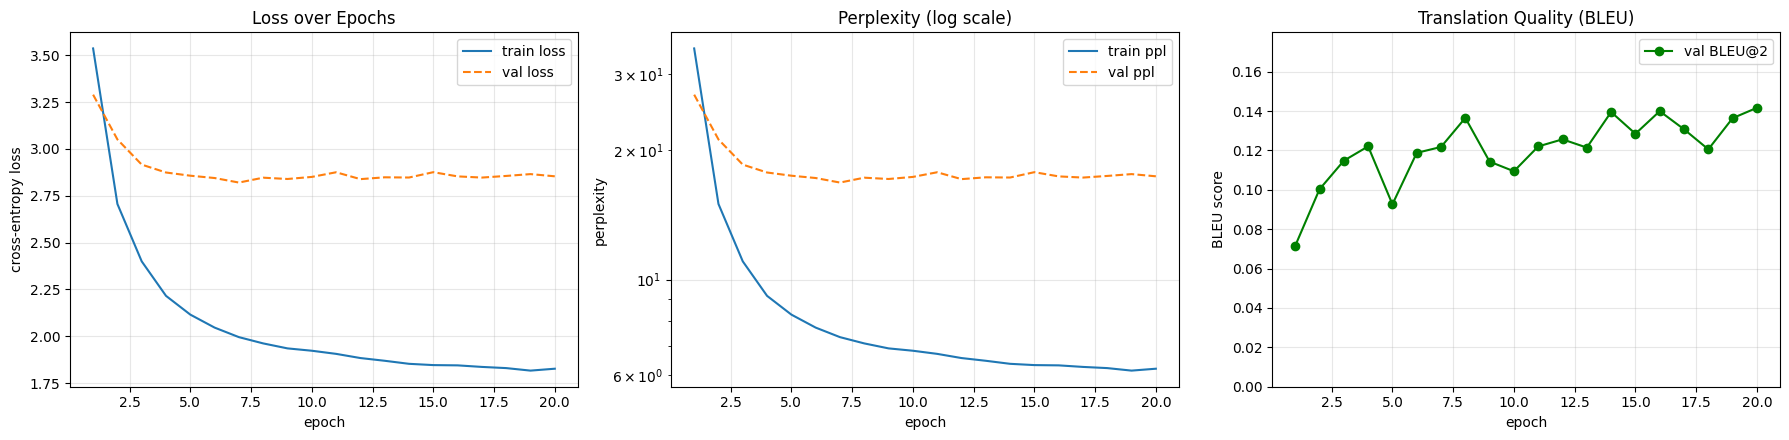

In [ ]:
import requests, math, time, re, collections, torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

class Seq2Seq(nn.Module):
  def __init__(self, src_vocab_size, tgt_vocab_size, embed_size=256, num_hiddens=256, num_layers=2, dropout_p=0.2):
    super().__init__()
    self.num_hiddens, self.num_layers = num_hiddens, num_layers
    self.src_embed, self.tgt_embed = nn.Embedding(src_vocab_size, embed_size), nn.Embedding(tgt_vocab_size, embed_size)
    self.encoder = nn.GRU(embed_size, num_hiddens, num_layers, dropout=dropout_p)
    self.decoder = nn.GRU(embed_size + num_hiddens, num_hiddens, num_layers, dropout=dropout_p)
    self.dropout_ctx, self.dropout_out = nn.Dropout(dropout_p), nn.Dropout(dropout_p)
    self.head = nn.Linear(num_hiddens, tgt_vocab_size)
  def forward(self, src, tgt_in): #src,tgt_in=(batch_size, num_steps)
    enc_out, state = self.encoder(self.src_embed(src).transpose(0,1)) #GRU[0]=(num_steps, batch_size, num_hiddens)
    context = enc_out[-1].unsqueeze(0).expand(tgt_in.shape[1], -1, -1) #context=(num_steps, batch_size, num_hiddens)
    dec_in = torch.cat([self.tgt_embed(tgt_in).transpose(0,1), self.dropout_ctx(context)], dim=-1)
    dec_out, _ = self.decoder(dec_in, state) #dec_out=(num_steps, batch_size, num_hiddens)
    return self.head(self.dropout_out(dec_out)).transpose(0,1) #return=(batch_size, num_steps, tgt_vocab)
  def loss(self, logits, labels, pad_idx):
    loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels.reshape(-1), label_smoothing=0.02, reduction='none')
    mask = (labels.reshape(-1)!=pad_idx).float()
    return (loss * mask).sum() / mask.sum()
  def predict(self, src, tgt_bos, tgt_eos, num_steps): #src=(batch_size, num_steps)
    self.eval()
    enc_out, state = self.encoder(self.src_embed(src).transpose(0,1))
    context, out = enc_out[-1].unsqueeze(0), []
    prev_step = torch.full((src.shape[0], 1), tgt_bos, dtype=torch.long, device=src.device) #prev_step=(batch_size, 1)
    for _ in range(num_steps):
      dec_in = torch.cat([self.tgt_embed(prev_step).transpose(0,1), context], dim=-1)
      dec_out, state = self.decoder(dec_in, state)
      logits = self.head(dec_out[-1]) #logits=(batch_size, tgt_vocab)
      prev_step = logits.argmax(-1, keepdim=True)
      out.append(prev_step) #out=[(batch_size, 1)]
      if (prev_step == tgt_eos).all(): break
    return torch.cat(out, dim=1) #return=(batch_size, <=num_steps)

class Vocab:
  def __init__(self, batch_size=64, num_steps=32, num_train=50000, num_test=10000,
               url="http://d2l-data.s3-accelerate.amazonaws.com/fra-eng.zip"):
    self.batch_size, self.num_steps, self.num_train, self.num_test = batch_size, num_steps, num_train, num_test
    lines = self._download(url)
    src_lines, tgt_lines = [], []
    for line in (line for i, line in enumerate(lines) if i<num_train+num_test):
      parts = line.split('\t')
      if len(parts)==2:
        src_lines.append(parts[0])
        tgt_lines.append(parts[1])
    src_tokens = [[t for t in f'{line} <eos>'.split() if t] for line in src_lines]
    tgt_tokens = [[t for t in f'{line} <eos>'.split() if t] for line in tgt_lines]
    self._build_vocab(src_tokens, tgt_tokens)
    self._build_tensors(src_tokens, tgt_tokens)
  @staticmethod
  def _download(url):
    r = requests.get(url)
    r.raise_for_status()
    with open('en-fr.zip', 'wb') as f:
      f.write(r.content)
    import zipfile
    with zipfile.ZipFile('en-fr.zip', 'r') as zip_ref:
      zip_ref.extractall('tatoeba_data')
    with open('tatoeba_data/fra-eng/fra.txt', 'r', encoding='utf-8') as f:
      raw_text = f.read()
    text = raw_text.replace('\u202f',' ').replace('\xa0',' ')
    out = [' ' + char if i>0 and char in ',.!?' and text[i-1]!=' ' else char for i, char in enumerate(text.lower())]
    return ''.join(out).split('\n')
  def _build_vocab(self, src_tokens, tgt_tokens, min_freq=2):
    reserved = ['<pad>', '<bos>', '<eos>', '<unk>']
    src_counter = collections.Counter(token for line in src_tokens for token in line)
    self.src_idx_to_token = reserved + [t for t in sorted([t for t, c in src_counter.items() if c >= min_freq])]
    self.src_token_to_idx = {t:i for i, t in enumerate(self.src_idx_to_token)}
    tgt_counter = collections.Counter(token for line in tgt_tokens for token in line)
    self.tgt_idx_to_token = reserved + [t for t in sorted([t for t, c in tgt_counter.items() if c >= min_freq])]
    self.tgt_token_to_idx = {t:i for i, t in enumerate(self.tgt_idx_to_token)}
  def _build_tensors(self, src_tokens, tgt_tokens):
    X, Y, valid_lens, four = [], [], [], lambda idx:(idx['<pad>'], idx['<unk>'], idx['<eos>'], idx['<bos>'])
    src_pad, src_unk, src_eos, _ = four(self.src_token_to_idx)
    tgt_pad, tgt_unk, tgt_eos, tgt_bos = four(self.tgt_token_to_idx)
    for src, tgt in zip(src_tokens, tgt_tokens):
      src_idx = [self.src_token_to_idx.get(t, src_unk) for t in src]
      tgt_idx = [self.tgt_token_to_idx.get(t, tgt_unk) for t in tgt]
      src_idx = src_idx[:self.num_steps] if len(src_idx)>self.num_steps else src_idx + [src_pad] * (self.num_steps - len(src_idx))
      tgt_idx = tgt_idx[:self.num_steps] if len(tgt_idx)>self.num_steps else tgt_idx + [tgt_pad] * (self.num_steps - len(tgt_idx))
      X.append(src_idx)
      Y.append([tgt_bos] + tgt_idx)
      valid_lens.append((torch.tensor(src_idx)!=src_pad).sum().item())
    self.X, self.tgt_array, self.src_valid_len = torch.tensor(X), torch.tensor(Y), torch.tensor(valid_lens, dtype=torch.int32)
  def __len__(self):
    return len(self.src_idx_to_token), len(self.tgt_idx_to_token)
  def get_dataloader(self, train=True):
    idx = slice(0, self.num_train) if train else slice(self.num_train, self.num_train+self.num_test)
    return DataLoader(TensorDataset(self.X[idx],
                                    self.tgt_array[idx, :-1],
                                    self.src_valid_len[idx],
                                    self.tgt_array[idx, 1:]), batch_size=self.batch_size, shuffle=train)
  def get_bleudataloader(self, n_examples=100):
    idx = slice(self.num_train, self.num_train + min(n_examples, self.num_test))
    return DataLoader(TensorDataset(self.X[idx],
                                    self.tgt_array[idx, :-1],
                                    self.src_valid_len[idx],
                                    self.tgt_array[idx, 1:]), batch_size=self.batch_size, shuffle=False)
  def src_to_tokens(self, indices):
    return [self.src_idx_to_token[int(i)] for i in indices]
  def tgt_to_tokens(self, indices):
    return [self.tgt_idx_to_token[int(i)] for i in indices]

def train_epoch(model, data_loader, optimizer, device, pad_idx):
  model.train()
  total_loss, total_tokens = 0.0, 0
  for src, tgt_in, src_valid_len, tgt_out in data_loader:
    src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)
    optimizer.zero_grad()
    logits = model(src, tgt_in)
    loss = model.loss(logits, tgt_out, pad_idx)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # Prevent exploding gradients
    optimizer.step()
    num_tokens = (tgt_out != pad_idx).sum().item()
    total_loss += loss.item() * num_tokens
    total_tokens += num_tokens
  return total_loss / total_tokens

def evaluate(model, data_loader, device, pad_idx):
  model.eval()
  total_loss, total_tokens = 0.0, 0
  with torch.no_grad():
    for src, tgt_in, src_valid_len, tgt_out in data_loader:
      src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)
      logits = model(src, tgt_in)
      loss = model.loss(logits, tgt_out, pad_idx)
      num_tokens = (tgt_out != pad_idx).sum().item()
      total_loss += loss.item() * num_tokens
      total_tokens += num_tokens
  return total_loss / total_tokens

def bleu(model, data, device):
  model.eval()
  total_bleu, n_pairs, tgt_bos, tgt_eos = 0.0, 0, data.tgt_token_to_idx['<bos>'], data.tgt_token_to_idx['<eos>']
  def bleu_tokens(pred_tokens, ref_tokens, k=2):
    score = math.exp(min(0, 1 - len(ref_tokens) / max(len(pred_tokens), 1))) # bp
    for n in range(1, k+1):
      num_matches, ref_counter = 0, collections.defaultdict(int)
      for i in range(len(ref_tokens)-n+1): #populate counter for all n-grams in ref
        ref_counter[' '.join(ref_tokens[i:i+n])] += 1
      for i in range(len(pred_tokens)-n+1):
        if ref_counter[' '.join(pred_tokens[i:i+n])] > 0:
          num_matches += 1
          ref_counter[' '.join(pred_tokens[i:i+n])] -= 1
      score *= math.pow(num_matches / max(len(pred_tokens)-n+1, 1e-7), 0.5**n)
    return score
  with torch.no_grad():
    for src, tgt_in, src_valid_len, tgt_out in data.get_bleudataloader():
      src = src.to(device)
      pred_indices = model.predict(src, tgt_bos, tgt_eos, data.num_steps)
      for i in range(src.shape[0]): #batch_size
        pred_tokens = [t for t in data.tgt_to_tokens(pred_indices[i].cpu().tolist()) if t not in ['<pad>', '<bos>', '<eos>', '<unk>']]
        ref_tokens = [t for t in data.tgt_to_tokens(tgt_out[i].cpu().tolist()) if t not in ['<pad>', '<eos>', '<bos>', '<unk>']]
        total_bleu += bleu_tokens(pred_tokens, ref_tokens)
        n_pairs += 1
  return total_bleu / max(n_pairs, 1)

def train(model, data, num_epochs, lr=0.005, device='cpu'):
  model.to(device)
  optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
  pad_idx, tgt_bos, tgt_eos = data.tgt_token_to_idx['<pad>'], data.tgt_token_to_idx['<bos>'], data.tgt_token_to_idx['<eos>']
  epochs, train_losses, val_losses, val_bleus = [], [], [], []
  for epoch in range(num_epochs):
    train_losses.append(train_epoch(model, data.get_dataloader(train=True), optimizer, device, pad_idx))
    val_losses.append(evaluate(model, data.get_dataloader(train=False), device, pad_idx))
    val_bleus.append(bleu(model, data, device))
    epochs.append(epoch + 1)
    if (epoch + 1) % 5 == 0 or epoch == 0:
      print(f'Epoch {epoch+1:3d} | train loss {train_losses[-1]:.4f} (ppl {math.exp(train_losses[-1]):.2f}) | val loss {val_losses[-1]:.4f} (ppl {math.exp(val_losses[-1]):.2f}) | bleu {val_bleus[-1]:.4f}')
      src_sample = data.X[0:1].to(device)
      pred_indices = model.predict(src_sample, tgt_bos, tgt_eos, data.num_steps)
      src_tokens = [t for t in data.src_to_tokens(data.X[0].cpu().tolist()) if t not in ['<pad>', '<eos>']]
      pred_tokens = [t for t in data.tgt_to_tokens(pred_indices[0].cpu().tolist()) if t not in ['<pad>', '<eos>']]
      print(f'  sample: {" ".join(src_tokens)}: {" ".join(pred_tokens)}\n')
  return epochs, train_losses, val_losses, val_bleus

def plot_results(epochs, train_losses, val_losses, val_bleus, save_path='seq2seq_training_curves.png'):
  fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
  axes[0].plot(epochs, train_losses, label='train loss')
  axes[0].plot(epochs, val_losses, label='val loss', linestyle='--')
  axes[0].set(xlabel='epoch', ylabel='cross-entropy loss', title='Loss over Epochs')
  axes[0].legend(); axes[0].grid(alpha=0.3)
  axes[1].plot(epochs, [math.exp(l) for l in train_losses], label='train ppl')
  axes[1].plot(epochs, [math.exp(l) for l in val_losses], label='val ppl', linestyle='--')
  axes[1].set(xlabel='epoch', ylabel='perplexity', title='Perplexity (log scale)')
  axes[1].set_yscale('log')
  axes[1].legend(); axes[1].grid(alpha=0.3)
  axes[2].plot(epochs, val_bleus, label='val BLEU@2', color='green', marker='o')
  axes[2].set(xlabel='epoch', ylabel='BLEU score', title='Translation Quality (BLEU)')
  axes[2].legend(); axes[2].grid(alpha=0.3)
  axes[2].set_ylim(0, max(val_bleus) * 1.2 + 0.01)
  fig.tight_layout()
  fig.savefig(save_path, dpi=100)
  plt.show()

data = Vocab()
src_vocab_size, tgt_vocab_size = len(data.src_idx_to_token), len(data.tgt_idx_to_token)
print(f'Source Vocab: {src_vocab_size} | Target Vocab: {tgt_vocab_size}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = Seq2Seq(src_vocab_size, tgt_vocab_size)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,} | Device: {device}\n')
epochs, train_losses, val_losses, val_bleus = train(model, data, num_epochs=20, device=device)
plot_results(epochs, train_losses, val_losses, val_bleus)

# D2L 11: Attention